# Composite FISTA with rational momentum

Let $\mathcal H$ be a nonzero real Hilbert space, $L>0$, $R\geq0$, and $N\geq1$ an integer. Let $f$ be convex with $L$-Lipschitz gradient and $g$ be closed, proper and convex. Assume $0\in\nabla f(x_{\star})+\partial g(x_{\star})$ and $\|x_{0}-x_{\star}\|\leq R$. Write $F=f+g$; no initial value of $g(x_{0})$ is needed.

Initialize $y_{0}=x_{0}$ and, for $k=0,\ldots,N-1$, set
$$y_{k+1}=\operatorname{prox}_{g/L}\left(x_{k}-\frac1L\nabla f(x_{k})\right),\qquad
x_{k+1}=y_{k+1}+\frac{k}{k+3}(y_{k+1}-y_{k}).$$
Here $\operatorname{prox}_{g/L}(v)=\arg\min_{w}\{g(w)+\frac L2\|w-v\|^2\}$.
The requested performance metric is $F(y_{N})-F(x_{\star})$.

This notebook preserves the original evaluation. Saved numerical solves are replayed; certificate reconstruction and symbolic proof checks are rerun locally. This maintenance pass is not a new independent evaluation.


## Proof Statement

### Theorem and the paper's potential

Under the assumptions and updates above, for every integer $N\geq1$,
$$F(y_N)-F(x_\star)\leq\frac{2LR^2}{N^2+5N+2}.$$

Set $\tau_N=2/(N^2+5N+2)$ and
$$a_k=\frac{(k+1)[2N(N+1)(k+4)-k(k+2)(k+3)]}{N(N+1)[2N^2+10N+4-k^2-7k]}\quad(0\leq k<N),\qquad a_{-1}=0,\quad a_N=1,\quad b_k=a_k-a_{k-1}.$$
Define
$$D_0=\frac{N^2+5N+2}{4},\qquad D_k=\frac{2N^2+10N+2-k^2-5k}{8}\quad(1\leq k\leq N),$$
$$\widetilde a_0=0,\quad \widetilde a_k=\frac{D_k+1}{D_k}a_{k-1},\quad
\widetilde b_k=\widetilde a_k-\widetilde a_{k-1}\quad(1\leq k\leq N),\qquad
\delta_k=\frac{(k+2)(N-k)(N+k+1)}{2N(N+1)}\quad(0\leq k<N).$$
In particular, $a_N=\widetilde a_N=1$ and $D_0=2D_N=1/(2\tau_N)$. Define $Y_k=(y_k-x_\star)/D_k\in\mathcal H$ for $0\leq k\leq N$. For $1\leq k<N$,
$$\boldsymbol w_k=\begin{bmatrix}Y_k\\x_k-x_\star\end{bmatrix}\in\mathcal H^2,\qquad
\boldsymbol d_k=\frac12\begin{bmatrix}-\widetilde a_kD_k\\a_k\end{bmatrix}\in\mathbb R^2,\qquad
\mathbf Q_k=\begin{bmatrix}
D_N-\widetilde a_kD_k+\dfrac{(\widetilde a_kD_k)^2-\delta_k^2}{2a_k}&-\widetilde a_kD_k/2\\
-\widetilde a_kD_k/2&a_k/2
\end{bmatrix}\in\mathbb R^{2\times2}.$$
The potential is defined once by
$$V_0=0,\qquad V_N=F(y_N)-F(x_\star)-\tau_NL\|x_0-x_\star\|^2,$$
$$V_k=a_k[f(x_k)-f(x_\star)]+\widetilde a_k[g(y_k)-g(x_\star)]
-\tau_NL\|x_0-x_\star\|^2
-2\langle\nabla f(x_k),\boldsymbol d_k^\top\boldsymbol w_k\rangle
+L\boldsymbol w_k^\top \mathbf Q_k\boldsymbol w_k\quad(1\leq k<N).$$
The interior checkpoint uses the smooth oracle at $x_k$ and the proximal function value at $y_k$. No value of $g(y_0)$ is needed.

For $0\leq k<N-1$, set
$$\alpha_k=\frac{a_k(D_{k+1}+1)^2}{2}-D_N-\frac{kD_k\delta_{k+1}}{k+3}
-\frac{a_{k+1}k^2D_k^2}{2(k+3)^2},$$
and separately set
$$\alpha_{N-1}=\frac{D_N(D_N-1)}2
=\frac{(N-1)(N+6)(N^2+5N+2)}{128}.$$
The weights $a_k,b_k$ are positive for $0\leq k\leq N$, and $\widetilde a_k,\widetilde b_k$ are positive for $1\leq k\leq N$. The square weights satisfy $\alpha_0=0$, $\alpha_k>0$ for $1\leq k<N-1$, and $\alpha_{N-1}>0$ for $N\geq2$. All denominators are positive on these ranges. The decrements below therefore make $V_k$ nonincreasing.


### Proof outline and exact decrement identities

Use the potential defined in the theorem above. The nonpositive, unnormalized interpolation residuals are
$$\mathcal I_f(p,q)=f(q)-f(p)+\langle\nabla f(q),p-q\rangle
+\frac{\|\nabla f(p)-\nabla f(q)\|^2}{2L},$$
$$\mathcal I_g(p,y_{k+1})=g(y_{k+1})-g(p)
+\langle L(x_k-y_{k+1})-\nabla f(x_k),p-y_{k+1}\rangle.$$
The latter uses the subgradient from this specific proximal update, even if indexed iterates coincide. Composite stationarity does not require the smooth gradient or selected nonsmooth subgradient at $x_\star$ to vanish.

Write $\widehat x_{k+1}=x_{k+1}$ for $k<N-1$ and $\widehat x_N=y_N$. For $0\leq k<N$, define
$$\mathcal T_k=a_k\mathcal I_f(x_k,\widehat x_{k+1})
+b_{k+1}\mathcal I_f(x_\star,\widehat x_{k+1})
+\widetilde a_k\mathcal I_g(y_k,y_{k+1})
+\widetilde b_{k+1}\mathcal I_g(x_\star,y_{k+1}),$$
where the entire $\widetilde a_0$ term is omitted, and
$$s_k=\frac{\nabla f(x_k)-\nabla f(\widehat x_{k+1})}{L}
+Y_{k+1}-(x_k-y_{k+1}),$$
$$S_k=\frac{La_k}{2}\|s_k\|^2
+\frac{b_{k+1}}{2L}\|\nabla f(\widehat x_{k+1})-\nabla f(x_\star)\|^2
+L\alpha_k\|Y_{k+1}-Y_k\|^2.$$
For $1\leq k<N-1$, Code Cells 18 and 20 establish $\mathcal T_k-(V_{k+1}-V_k)=L\boldsymbol r_k^\top\mathbf S_k\boldsymbol r_k=S_k$ using the five-component state and matrix defined in Step 1 below. The last component retains $\nabla f(x_\star)$.

For $N\geq2$, the exact identities are
$$V_1-V_0=\mathcal T_0-S_0+b_0\mathcal I_f(x_\star,x_0)
-\frac{b_0}{2L}\|\nabla f(x_0)-\nabla f(x_\star)\|^2,$$
$$V_{k+1}-V_k=\mathcal T_k-S_k\quad(1\leq k<N-1),\qquad
V_N-V_{N-1}=\mathcal T_{N-1}-S_{N-1}.$$
For $N=1$, apply the first identity with the terminal choice $\widehat x_1=y_1$ and the terminal potential $V_1$. These identities, the interpolation inequalities, and the coefficient signs imply $V_N\leq V_0=0$. The endpoint relation
$$F(y_N)-F(x_\star)-\tau_NLR^2
=V_N+\tau_NL(\|x_0-x_\star\|^2-R^2)\leq0$$
gives the rate without dividing by $R$.

### Numerical discovery and the paper potential

Code Cells 2 through 16 replay the saved numerical solve and construct partial sums from a particular grouping of the interpolation residuals. Those intermediate sums are distinct from the paper's $V_k$ because the smooth interpolation terms are redistributed. Their full-horizon certificate and the paper's endpoint agree. Code Cell 18 checks the exact redistribution, while Code Cells 17 through 24 verify the paper's literal $V_k$ and decrements directly.


In [1]:
# Local imports resolve through the example path added to sys.path below.
import sys

sys.dont_write_bytecode = True
from pathlib import Path  # noqa: E402 - imports follow runtime setup or their proof block
import json  # noqa: E402 - imports follow runtime setup or their proof block
import numpy as np  # noqa: E402 - imports follow runtime setup or their proof block
import sympy as sp  # noqa: E402 - imports follow runtime setup or their proof block
import matplotlib.pyplot as plt  # noqa: E402 - imports follow runtime setup or their proof block
from IPython.display import Image, display  # noqa: E402 - imports follow runtime setup or their proof block

# Locate this example when opened from the notebook, supplementary, or repo directory.
_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next(
    candidate
    for location in _locations
    for candidate in (
        location,
        location / "examples_peppy/fista_rational_tight",
    )
    if (candidate / "fista_rational_tight_setup.py").is_file()
)
sys.path.insert(0, str(ROOT))
NOTEBOOK_DIR = ROOT
REPO_ROOT = next(
    directory
    for directory in ROOT.parents
    if (directory / "pepflow").is_dir() and (directory / "pyproject.toml").is_file()
)

sys.path.insert(0, str(REPO_ROOT))
import pepflow as pf  # noqa: E402
from supplementary.solve_utils import SOLVER_SETTINGS, capture, inventory, solve  # noqa: E402  # ty: ignore[unresolved-import]

assert Path(pf.__file__).resolve() == REPO_ROOT / "pepflow/__init__.py"
REVIEW_DIR = ROOT / "supplementary/compliance_review"
print("Imported repository PEPFlow")
print("Replaying the saved evaluation certificate; no new PEP solves requested.")

Imported repository PEPFlow
Replaying the saved evaluation certificate; no new PEP solves requested.


## Function and parameter definitions

Stationarity is imposed on the sum $F$; the smooth gradient and selected subgradient at the solution may be nonzero.

In [2]:
"""Composite FISTA with momentum k/(k+3) and a radius R distance bound."""

L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)
g = pf.ConvexFunction(is_basis=True, tags=["g"])
F = f + g

## Algorithm and PEP setup

The parameter $R$ denotes a radius. The squared distance constraint therefore uses $R^2$.

In [3]:
def make_ctx_fista_rational_tight(ctx_name, N, **kwargs):
    """Encode every proximal point; never evaluate g at the initial point."""
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0", "y_0"])
    F.set_stationary_point("x_star")
    y = x
    for k in range(int(N)):
        y_next = g.prox(x - f.grad(x) / L, 1 / L, tag=f"y_{k + 1}")
        f(y_next)
        if k == 0:
            x_next = y_next
        else:
            x_next = y_next + sp.Rational(k, k + 3) * (y_next - y)
        x_next.add_tag(f"x_{k + 1}")
        x, y = x_next, y_next
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_fista_rational_tight(f"fista_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(F(ctx[f"y_{N}"]) - F(ctx["x_star"]))
    return ctx, pb, f

## Numerical evidence

The dense PEP sweep uses $L=R=1$. Solver statuses are retained exactly, including any accuracy warning. Agreement with the conjecture is evidence at these seven horizons only.

N=1: PEP=0.2500000000, bound=0.2500000000, optimal
N=2: PEP=0.1250000000, bound=0.1250000000, optimal_inaccurate
N=3: PEP=0.0769230768, bound=0.0769230769, optimal_inaccurate
N=4: PEP=0.0526315780, bound=0.0526315789, optimal_inaccurate
N=5: PEP=0.0384615379, bound=0.0384615385, optimal_inaccurate
N=6: PEP=0.0294117638, bound=0.0294117647, optimal_inaccurate
N=7: PEP=0.0232558133, bound=0.0232558140, optimal_inaccurate


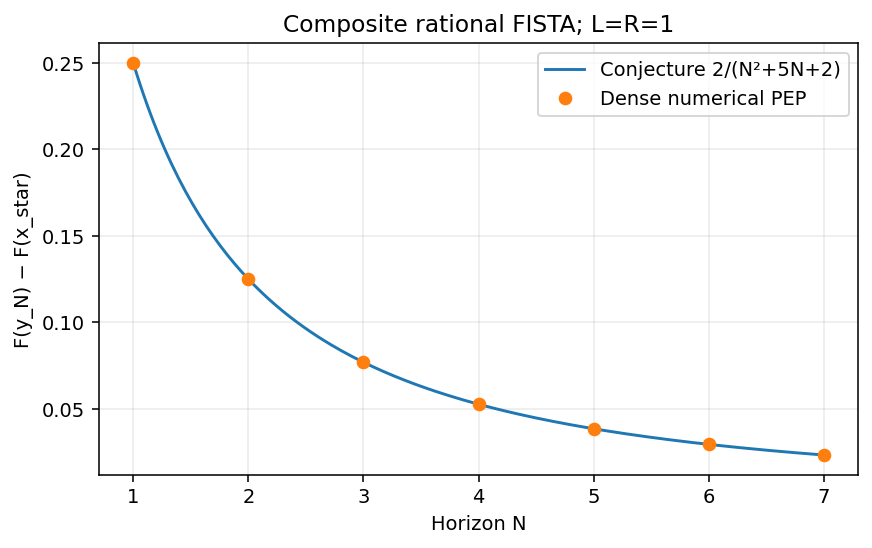

Reciprocal values: [ 4.          8.         13.00000002 19.00000034 26.0000004  34.00000103
 43.00000117]
Consecutive reciprocal differences: [4.         5.00000001 6.00000032 7.00000006 8.00000063 9.00000014]


In [4]:
REVIEW_DIR.mkdir(exist_ok=True)
sweep = json.loads((ROOT / "supplementary/sweep.json").read_text())
for row in sweep:
    print(
        f"N={row['N']}: PEP={row['opt_value']:.10f}, bound={row['conjectured']:.10f}, {row['solver_status']}"
    )
horizons = np.array([row["N"] for row in sweep])
values = np.array([row["opt_value"] for row in sweep])
grid = np.linspace(1, 7, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, 2 / (grid**2 + 5 * grid + 2), label="Conjecture 2/(N²+5N+2)")
ax.plot(horizons, values, "o", label="Dense numerical PEP")
ax.set(
    xlabel="Horizon N",
    ylabel="F(y_N) − F(x_star)",
    title="Composite rational FISTA; L=R=1",
)
ax.grid(alpha=0.25)
ax.legend()
fig.savefig(REVIEW_DIR / "rate_comparison.png", dpi=140, bbox_inches="tight")
display(Image(filename=str(REVIEW_DIR / "rate_comparison.png")))
plt.close(fig)
print("Reciprocal values:", 1 / values)
print("Consecutive reciprocal differences:", np.diff(1 / values))

## Dense and relaxed proof solves

The dense solve and local relaxation both give $1/34$ at $N=6$. The dense solve reports `optimal_inaccurate` at the stringent $10^{-10}$ tolerances; the selected relaxed certificate reports `optimal`. Its independently reconstructed identities have errors below $3\cdot10^{-11}$. All downstream numbers come from this one relaxed sample.

For step $j$, retain $I_{f}(\star,x_{j-1})$, $I_{f}(\star,y_{j})$, $I_{f}(x_{j-1},y_{j})$, $I_{g}(\star,y_{j})$, and, for $j>1$, $I_{f}(y_{j-1},x_{j-1})$ and $I_{g}(y_{j-1},y_{j})$. Identical-point inequalities are absent. Here $I_{f}(u,v)\leq0$ and $I_{g}(u,v)\leq0$ are the smooth-convex and convex interpolation residuals, respectively.
The displayed solve results are preserved from the original evaluation. The executable regeneration path remains visible and disabled; this replay verifies the stored certificate without launching a new solver run.


In [5]:
N_int = 6
params_sp = {"L": 1, "R": 1}
dense = json.loads((ROOT / "state/fista_rational_tight_dense.json").read_text())
certificate = json.loads((ROOT / "state/fista_rational_tight_b2.json").read_text())
# To regenerate, build this setup and use the exact one-thread solve API below.
REGENERATE_CERTIFICATE = False
if REGENERATE_CERTIFICATE:
    dense_ctx, dense_pb, _ = get_pep_setup(N_int, params_sp)
    dense_result, dense_problem = solve(dense_ctx, dense_pb, params_sp)
    dense = capture(dense_ctx, dense_pb, dense_result)
ctx, pb, obj = get_pep_setup(N_int, params_sp)
keep = {"initial_condition"}


def keep_pair(owner, a_tag, b_tag):
    if ctx[a_tag] is not ctx[b_tag]:
        keep.add(f"{owner}:{ctx[a_tag]},{ctx[b_tag]}")


for k in range(N_int):
    keep_pair("f", "x_star", f"x_{k}")
    keep_pair("f", "x_star", f"y_{k + 1}")
    keep_pair("f", f"x_{k}", f"y_{k + 1}")
    keep_pair("g", "x_star", f"y_{k + 1}")
    if k >= 1:
        keep_pair("f", f"y_{k}", f"x_{k}")
        keep_pair("g", f"y_{k}", f"y_{k + 1}")
pb.set_relaxed_constraints(
    [c.name for c, *_ in inventory(ctx, pb) if c.name not in keep]
)
assert set(pb.relaxed_constraints) == set(certificate["relaxed_constraints"])
if REGENERATE_CERTIFICATE:
    relaxed_result, relaxed_problem = solve(ctx, pb, params_sp)
    regenerated = capture(ctx, pb, relaxed_result)
    assert abs(regenerated["opt_value"] - certificate["opt_value"]) < 1e-5
print("Solver settings:", SOLVER_SETTINGS)
print("Dense:", dense["opt_value"], dense["solver_status"])
print("Relaxed:", certificate["opt_value"], certificate["solver_status"])
print("Dense-relaxed difference:", abs(dense["opt_value"] - certificate["opt_value"]))
print("Basis vectors:", certificate["basis_vectors"])
for data, label in [(dense, "dense"), (certificate, "relaxed")]:
    for owner in ("f", "g"):
        entries = [
            (name, val)
            for name, val in data["named_dual_values"].items()
            if name.startswith(owner + ":") and val is not None and abs(val) > 1e-6
        ]
        print(
            label,
            owner,
            "nonzero inequalities:",
            len(entries),
            "range:",
            (min(v for _, v in entries), max(v for _, v in entries)),
        )
for name, value in certificate["named_dual_values"].items():
    if value is not None:
        print(name, f"{value:.9f}")

Solver settings: {'solver': 'CLARABEL', 'max_threads': 1, 'tol_gap_abs': 1e-10, 'tol_gap_rel': 1e-10, 'tol_feas': 1e-10, 'max_iter': 300}
Dense: 0.029411763811233695 optimal_inaccurate
Relaxed: 0.029411764704745606 optimal
Dense-relaxed difference: 8.935119102937428e-10
Basis vectors: ['y_0', 'x_star', 'grad_f(x_star)', 'grad_f(y_0)', 'grad_g(y_1)', 'grad_f(y_1)', 'grad_g(y_2)', 'grad_f(y_2)', 'grad_f(x_2)', 'grad_g(y_3)', 'grad_f(y_3)', 'grad_f(x_3)', 'grad_g(y_4)', 'grad_f(y_4)', 'grad_f(x_4)', 'grad_g(y_5)', 'grad_f(y_5)', 'grad_f(x_5)', 'grad_g(y_6)', 'grad_f(y_6)']
dense f nonzero inequalities: 132 range: (2.4531519777860087e-06, 0.43601254810587325)
dense g nonzero inequalities: 36 range: (0.002056599256326723, 0.673235559763769)
relaxed f nonzero inequalities: 21 range: (0.010119280408260026, 0.8947370986380517)
relaxed g nonzero inequalities: 11 range: (0.06249996977265467, 0.7142860909953936)
initial_condition 0.029411765
f:x_star,y_0 0.058823525
f:x_star,x_1 0.092962302
f:x_s

### Labeled multiplier matrices

Both function classes are shown for the dense and selected relaxed solves. Displayed zeros include diagonal entries and removed constraints; the complete saved inventory retains removed multipliers as null. Six-column blocks keep the labels readable.

In [6]:
for data, solve_label in [(dense, "Dense"), (certificate, "Relaxed")]:
    for owner in (f, g):
        labels = [str(point) for point in ctx.tracked_point(owner)]
        matrix = np.zeros((len(labels), len(labels)))
        for i, first in enumerate(labels):
            for j, second in enumerate(labels):
                value = data["named_dual_values"].get(f"{owner}:{first},{second}")
                if value is not None:
                    matrix[i, j] = value
        print(solve_label, str(owner), "multipliers")
        for start in range(0, len(labels), 6):
            pf.pprint_labeled_matrix(
                matrix[:, start : start + 6],
                labels,
                labels[start : start + 6],
                precision=5,
            )

Dense f multipliers


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Dense g multipliers


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (2 outputs left out)

<IPython.core.display.Math object>

Relaxed g multipliers


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Lambda and S verification

The certificate uses the convention
$$F(y_{N})-F(x_{\star})-\tau R^2-\sum_{c}\lambda_{c} I_{c}+S=0.$$
The initial residual is $I_{\mathrm{init}}=\|x_{0}-x_{\star}\|^2-R^2$. The numerical check includes every Gram coefficient, function-value coefficient, constant, and inequality multiplier. The complete constraint inventory and saved certificate digest are revalidated below.

In [7]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pepflow as pf

certificate_checked = False
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
digest = hashlib.sha256(
    json.dumps(
        {key: certificate[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    ).encode()
).hexdigest()
assert digest == certificate["certificate_id"]
assert certificate["closed_form_search"]["completed"]
assert certificate["certificate_provenance"]["pep_type"] == "primal"
assert Path(pf.__file__).resolve() == REPO_ROOT / "pepflow" / "__init__.py"
assert N_int == certificate["N_verify"]
assert params_sp == json.loads(certificate["params_json"])
assert pb.ctx is ctx
assert set(pb.relaxed_constraints) == set(certificate["relaxed_constraints"])
basis = list(ctx.basis_vectors())
basis_labels = [str(v) for v in basis]
assert (
    basis_labels
    == certificate["basis_vectors"]
    == certificate["S_row_names"]
    == certificate["S_col_names"]
)
assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
tol = certificate["numerical_checks"]["tolerances"]
S_array = np.asarray(certificate["S_matrix"], dtype=float)
assert np.all(np.isfinite(S_array)) and S_array.shape == (len(basis), len(basis))
assert np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0)
assert np.linalg.eigvalsh(S_array).min() >= -tol["psd_tol"]
S_sol = pf.MatrixWithNames(S_array, basis_labels, basis_labels)
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)
records = [(c, "initial", None, None) for c in pb.init_conditions]
for owner in ctx.func_to_triplets:
    groups = ctx.get_constraint_data(owner)
    records.extend(
        (c, "interpolation", str(owner), str(group))
        for group, family in groups.sc_dict.items()
        for c in family
    )
    records.extend(
        (c, "interpolation", str(owner), str(group))
        for group, c in groups.psd_dict.items()
    )
assert len({c.name for c, *_ in records}) == len(records)
assert (
    {c.name for c, *_ in records}
    == set(certificate["constraint_metadata"])
    == set(certificate["named_dual_values"])
)
weighted_terms, interpolation_terms, extra_terms, extra_duals = {}, {}, {}, {}
constraints_by_name = {}
saved_duals = certificate["named_dual_values"]
tau_name = certificate["tau_name"]
for c, origin, owner, group in records:
    assert isinstance(c, pf.ScalarConstraint), (
        "This case has only scalar interpolation inequalities."
    )
    constraints_by_name[c.name] = c
    dropped = c.name in pb.relaxed_constraints
    expected_meta = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar",
        comparator=c.cmp.value,
        shape=[],
        relaxed=dropped,
    )
    assert certificate["constraint_metadata"][c.name] == expected_meta
    value = saved_duals[c.name]
    if dropped:
        assert value is None
        continue
    assert value is not None and np.isfinite(value)
    if c.cmp != pf.Comparator.EQ:
        assert value >= -tol["dual_tol"]
    residual = c.lhs - c.rhs
    if c.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted_terms[c.name] = float(value) * residual
    if origin == "interpolation":
        interpolation_terms[c.name] = weighted_terms[c.name]
    elif c.name != tau_name:
        extra_terms[c.name] = weighted_terms[c.name]
        extra_duals[c.name] = value
assert certificate["normalization"]["initial_condition"] == "||x_0-x_star||^2 <= R^2"
assert certificate["normalization"]["performance_metric"] == "F(y_N)-F(x_star)"
assert abs(saved_duals[tau_name] - certificate["tau_sol"]) <= tol["dual_tol"]
assert (
    abs(certificate["normalization"]["bound_value"] - certificate["opt_value"])
    <= tol["identity_atol"]
)
certificate_diff = (
    pb.performance_metric
    - certificate["opt_value"]
    - sum(weighted_terms.values(), pf.Scalar.zero())
    + S_scalar
)
checked = pm.eval_scalar(certificate_diff)
certificate_residuals = {}
for label, coords in (
    ("Gram", checked.inner_prod_coords),
    ("function", checked.func_coords),
    ("offset", checked.offset),
):
    error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
    certificate_residuals[label] = error
    assert error <= tol["identity_atol"], (label, error)
D_saved = np.asarray(certificate["numerical_decomposition"]["D"], dtype=float)
E_saved = np.asarray(certificate["numerical_decomposition"]["ell_coords"], dtype=float)
assert certificate["numerical_decomposition"]["basis_labels"] == basis_labels
assert E_saved.shape[1] == len(basis) and D_saved.shape == (
    E_saved.shape[0],
    E_saved.shape[0],
)
assert np.all(np.isfinite(D_saved)) and np.all(np.isfinite(E_saved))
assert np.allclose(
    E_saved.T @ D_saved @ E_saved,
    S_array,
    atol=tol["reconstruction_atol"],
    rtol=tol["reconstruction_rtol"],
)
certificate_checked = True
print("Recomputed certificate residuals:", certificate_residuals)

Recomputed certificate residuals: {'Gram': 1.0788148152585109e-11, 'function': 2.626898698565583e-11, 'offset': 2.6640946393374776e-12}


### Initial closed-form search

At the sampled horizon, use the paper coefficients $D_j,a_j,\widetilde a_j,\widetilde b_j$, and $\tau_N$. The six candidate multipliers at step $j$, in the previously listed constraint order, are
$$a_{j-1}-\widetilde a_{j-1},\qquad \frac{a_{j-1}}{D_j},\qquad
a_{j-1},\qquad \widetilde b_j,\qquad
\widetilde a_{j-1},\qquad \widetilde a_{j-1}.$$
The second multiplier is a split of the selected numerical interpolation constraint; it is not the paper's $b_j$. Coincident constraints contribute additively. The candidate slack is the full weighted interpolation sum minus the performance metric plus $\tau_N$. This numerical search checks both function classes and every Gram, function-value, and constant component; the symbolic proof below establishes the all-horizon signs.


In [8]:
# Paper coefficients are shared by discovery and exact verification.
def tau_N(N):
    N = sp.sympify(N)
    return sp.S(2) / (N**2 + 5 * N + 2)


def D_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == 0:
        return (N**2 + 5 * N + 2) / 4
    return (2 * N**2 + 10 * N + 2 - k**2 - 5 * k) / 8


def a_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == -1:
        return sp.S(0)
    if k == N:
        return sp.S(1)
    return sp.factor(
        (k + 1)
        * (2 * N * (N + 1) * (k + 4) - k * (k + 2) * (k + 3))
        / (N * (N + 1) * (2 * N**2 + 10 * N + 4 - k**2 - 7 * k))
    )


def b_k(k, N):
    return sp.factor(a_k(k, N) - a_k(sp.sympify(k) - 1, N))


def tilde_a_k(k, N):
    k = sp.sympify(k)
    if k == 0:
        return sp.S(0)
    return sp.factor((D_k(k, N) + 1) * a_k(k - 1, N) / D_k(k, N))


def tilde_b_k(k, N):
    return sp.factor(tilde_a_k(k, N) - tilde_a_k(sp.sympify(k) - 1, N))


def delta_k(k, N):
    k, N = map(sp.sympify, (k, N))
    return (k + 2) * (N - k) * (N + k + 1) / (2 * N * (N + 1))


def alpha_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == N - 1:
        DN = D_k(N, N)
        return DN * (DN - 1) / 2
    return sp.factor(
        a_k(k, N) * (D_k(k + 1, N) + 1) ** 2 / 2
        - D_k(N, N)
        - k * D_k(k, N) * delta_k(k + 1, N) / (k + 3)
        - a_k(k + 1, N) * k**2 * D_k(k, N) ** 2 / (2 * (k + 3) ** 2)
    )


# This sampled multiplier is a_(j-1)/D_j; it is not the paper's b_j.
def sample_split_weight(j, N):
    return a_k(sp.sympify(j) - 1, N) / D_k(j, N)


def tilde_a_times_D(j, N):
    return tilde_a_k(j, N) * D_k(j, N)


def delta_at_proximal_index(j, N):
    return delta_k(sp.sympify(j) - 1, N)


def alpha_at_proximal_index(j, N):
    return alpha_k(sp.sympify(j) - 1, N)


def momentum_at_proximal_index(j):
    j = sp.sympify(j)
    return sp.S(0) if j == 1 else (j - 2) / (j + 1)


def half_a_before_index(j, N):
    return a_k(sp.sympify(j) - 1, N) / 2


def sample_y_quadratic_weight(k, N):
    return (tilde_a_k(k, N) * D_k(k + 1, N) - (delta_k(k, N) - 1)) / (2 * D_k(k, N))


def sample_endpoint_scale(j):
    j = sp.sympify(j)
    return sp.S(0) if j == 0 else (j * j + 5 * j + 2) / 8


for j in range(1, N_int + 1):
    print(
        f"j={j}: tilde_a_j={tilde_a_k(j, N_int)}, a_(j-1)/D_j={sample_split_weight(j, N_int)}"
    )
lambda_guess = {
    name: sp.sympify(value) for name, value in certificate["lambda_candidates"].items()
}
lambda_error = max(
    abs(float(value) - saved_duals[name]) for name, value in lambda_guess.items()
)
S_guess = (
    sum(
        (
            lambda_guess[c.name] * (c.lhs - c.rhs)
            for c, *_ in records
            if c.name in lambda_guess
        ),
        pf.Scalar.zero(),
    )
    - pb.performance_metric
    + tau_N(N_int)
)
S_guess_evaluated = pm.eval_scalar(S_guess)
print("Lambda candidate maximum error:", lambda_error)
print(
    "S candidate Gram error:",
    np.max(
        np.abs(np.asarray(S_guess_evaluated.inner_prod_coords, dtype=float) - S_array)
    ),
)
print(
    "S candidate function/offset:",
    np.max(np.abs(S_guess_evaluated.func_coords)),
    S_guess_evaluated.offset,
)
print("Formula status: numerical candidates; universal positivity not yet proved.")

j=1: tilde_a_j=1/16, a_(j-1)/D_j=1/272
j=2: tilde_a_j=17/105, a_(j-1)/D_j=17/1680
j=3: tilde_a_j=116/385, a_(j-1)/D_j=464/22715
j=4: tilde_a_j=166/343, a_(j-1)/D_j=664/18179
j=5: tilde_a_j=5/7, a_(j-1)/D_j=10/161
j=6: tilde_a_j=1, a_(j-1)/D_j=2/19
Lambda candidate maximum error: 7.48742902123567e-07
S candidate Gram error: 7.487425346397458e-07
S candidate function/offset: 2.77555756156289e-17 0
Formula status: numerical candidates; universal positivity not yet proved.


In [9]:
for owner in (f, g):
    labels = [str(point) for point in ctx.tracked_point(owner)]
    candidate_matrix = np.zeros((len(labels), len(labels)))
    for i, first in enumerate(labels):
        for j, second in enumerate(labels):
            candidate_matrix[i, j] = float(
                lambda_guess.get(f"{owner}:{first},{second}", 0)
            )
    print(str(owner), "closed-form candidate multipliers at N=6")
    for start in range(0, len(labels), 6):
        pf.pprint_labeled_matrix(
            candidate_matrix[:, start : start + 6],
            labels,
            labels[start : start + 6],
            precision=6,
        )

f closed-form candidate multipliers at N=6


<IPython.core.display.Math object>

<IPython.core.display.Math object>

g closed-form candidate multipliers at N=6


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Numerical square decomposition

The initial reverse-LDL factors reconstructed the selected $S$ to machine precision. Subsequent basis inspection suggested the local squares used below; their matrix differs from this same numerical $S$ by less than $7.5\cdot10^{-7}$. The saved bound and every numerical multiplier are unchanged. The direct decomposition was revalidated and the dependent partial sums rebuilt. The actual $S$ is displayed in five-column blocks.

In [10]:
D = D_saved
E = E_saved
ell = [sum((float(c) * v for c, v in zip(row, basis)), pf.Vector.zero()) for row in E]
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
print("Initial reverse-LDL diagonal:", np.diag(certificate["prior_decomposition"]["D"]))
print("Selected direct-square diagonal:", np.diag(D))
print("Reconstruction error:", np.max(np.abs(E.T @ D @ E - S_array)))
print("Minimum eigenvalue:", np.linalg.eigvalsh(S_array).min())
# Five-column blocks keep the true labeled matrix readable in the HTML preview.
for start in range(0, len(basis), 5):
    pf.pprint_labeled_matrix(
        S_array[:, start : start + 5], basis_labels, basis_labels[start : start + 5]
    )
pf.pprint_labeled_matrix(
    np.asarray(checked.inner_prod_coords, dtype=float),
    [f"v_{{{i}}}" for i in range(len(basis))],
    [f"v_{{{i}}}" for i in range(len(basis))],
)
print("Function residual:", checked.func_coords)
print("Constant residual:", checked.offset)
print("Numerical certificate verified:", certificate_checked)
print("Analytic full-PEP verified:", certificate["analytic_full_pep_verified"])

Initial reverse-LDL diagonal: [5.00000000e-01 5.00000000e-01 4.88919722e-01 4.53402554e-01
 1.45690582e-01 3.67202243e-01 3.24501283e-01 9.97882447e-02
 2.51290695e-01 2.10984312e-01 6.55418236e-02 1.55706627e-01
 1.19817522e-01 3.78451163e-02 8.24990968e-02 2.13658033e-02
 2.94117601e-02 4.24218265e-11 1.68477948e-12 1.41548309e-12]
Selected direct-square diagonal: [2.94117647e-02 2.94117647e-02 1.83823529e-03 0.00000000e+00
 7.58928571e-02 4.46428571e-02 5.05952381e-03 1.82445521e+00
 3.12500000e-02 1.40435835e-01 5.94834544e-02 1.02135153e-02
 3.28537736e+00 8.09523810e-02 2.23719677e-01 7.30703259e-02
 1.82628307e-02 4.56051048e+00 1.50649351e-01 3.26086957e-01
 8.41044492e-02 3.10559006e-02 5.70394737e+00 2.41982507e-01
 4.47368421e-01 9.02255639e-02 5.26315789e-02 3.18750000e+01
 3.57142857e-01]
Reconstruction error: 7.487425346397458e-07
Minimum eigenvalue: 9.83747400239386e-13


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Function residual: [ 2.62689870e-11  1.44915191e-11  0.00000000e+00 -2.08166817e-17
 -2.71396794e-12 -2.71399569e-12 -2.71399569e-12 -2.58165711e-12
 -2.58165711e-12 -2.58165711e-12 -2.30526709e-12 -2.30532260e-12
 -2.30537811e-12 -2.14561702e-12 -2.14561702e-12 -2.14561702e-12
 -2.03093098e-12 -4.74487116e-12 -4.74464912e-12]
Constant residual: 2.6640946393374776e-12
Numerical certificate verified: True
Analytic full-PEP verified: False


## Partial-sum Lyapunov construction

The selected numerical square decomposition uses the paper's $Y_j=(y_j-x_\star)/D_j$ and coefficient values. At step $k$, write the selected proximal subgradient explicitly as
$$L(x_k-y_{k+1})-\nabla f(x_k)\in\partial g(y_{k+1}).$$
At $L=1$, the local squares reconstructed from the saved certificate have weights $a_k/2$, $(a_k-\widetilde a_k)/2$, $a_k/(2D_{k+1})$, $\widetilde a_k/2$, and $\alpha_k$, respectively, on
$$\begin{aligned}
&\left\|\frac{\nabla f(y_{k+1})+L(x_k-y_{k+1})-\nabla f(x_k)}L-Y_{k+1}\right\|^2,\\
&\left\|\frac{\nabla f(x_k)-\nabla f(x_\star)}L\right\|^2,\qquad
\left\|\frac{\nabla f(y_{k+1})-\nabla f(x_\star)}L\right\|^2,\\
&\left\|\frac{\nabla f(y_k)-\nabla f(x_k)}L\right\|^2,\qquad
\|Y_{k+1}-Y_k\|^2.
\end{aligned}$$
The term with $\widetilde a_0=0$ is absent at the first step. The sampled signs are checked here; the symbolic proof below establishes the all-horizon signs.

At each step, accumulate its weighted interpolation residuals and subtract its local squares. For $N\geq2$, delay the positive first-step input-gradient square to the second step. Split the coincident inequality at $y_1=x_1$ into its two positive roles. The resulting sampled partial sums have constant interior rank three and no omitted or terminal leftover terms. They are distinct from the paper's $V_k$ at interior indices; the exact section checks their relationship and verifies the paper potential directly.


In [11]:
# Closed-form candidates, normalized at L=1; each piece is compared to the SAME S.
def sample_position_quadratic(k, n, ek, eprev):
    if k == n:
        return pf.Scalar.zero()
    x = (1 + momentum_at_proximal_index(k + 1)) * ek - momentum_at_proximal_index(
        k + 1
    ) * eprev
    cnext = half_a_before_index(k + 1, n)
    dnow = sample_y_quadratic_weight(k, n)
    return cnext * x**2 - tilde_a_k(k, n) * (ek * x) + dnow * ek**2


direct_factors, direct_weights, direct_steps = {}, {}, {}
for j in range(1, N_int + 1):
    ak, at_prev, split_weight = (
        a_k(j - 1, N_int),
        tilde_a_k(j - 1, N_int),
        sample_split_weight(j, N_int),
    )
    xp, y = ctx[f"x_{j - 1}"], ctx[f"y_{j}"]
    y_gap = y - ctx["x_star"]
    input_grad_gap = f.grad(xp) - f.grad(ctx["x_star"])
    output_grad_gap = f.grad(y) - f.grad(ctx["x_star"])
    proximal_residual = f.grad(y) + g.grad(y)
    local_factors = {
        f"residual:{j}": (proximal_residual - y_gap / D_k(j, N_int), ak / 2),
        f"input_gradient:{j}": (input_grad_gap, (ak - at_prev) / 2),
        f"output_gradient:{j}": (output_grad_gap, split_weight / 2),
        f"position_difference:{j}": (
            y_gap / D_k(j, N_int)
            - (ctx[f"y_{j - 1}"] - ctx["x_star"]) / D_k(j - 1, N_int),
            alpha_k(j - 1, N_int),
        ),
    }
    if j > 1:
        local_factors[f"gradient_difference:{j}"] = (
            f.grad(ctx[f"y_{j - 1}"]) - f.grad(xp),
            at_prev / 2,
        )
    for label, (vector, weight) in local_factors.items():
        direct_factors[label] = vector
        direct_weights[label] = weight
        direct_steps[label] = j - 1
# Delay one positive first-step square to the second step (when that step exists).
if N_int >= 2:
    direct_steps["input_gradient:1"] = 1
S_piece_terms = {
    label: weight * direct_factors[label] ** 2
    for label, weight in direct_weights.items()
}
factor_labels = list(direct_factors)
D = np.diag([float(direct_weights[label]) for label in factor_labels])
E = np.asarray(
    [pm.eval_vector(direct_factors[label]).coords for label in factor_labels],
    dtype=float,
)
ell = [direct_factors[label] for label in factor_labels]
assert min(direct_weights.values()) >= 0
S_numeric = sum(S_piece_terms.values(), pf.Scalar.zero())
direct_value = pm.eval_scalar(S_numeric - S_scalar)
direct_residuals = {}
for label, coords in (
    ("Gram", direct_value.inner_prod_coords),
    ("function", direct_value.func_coords),
    ("offset", direct_value.offset),
):
    error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
    direct_residuals[label] = error
    assert error <= tol["identity_atol"]
print("Direct local squares vs selected S:", direct_residuals)

Direct local squares vs selected S: {'Gram': 7.487425346397458e-07, 'function': 0.0, 'offset': 0.0}


In [12]:
# Every interpolation residual is <= 0; subtract only numerically PSD S pieces.
grouping_checked = False
rank_tolerance = 1e-4
group_terms = dict(interpolation_terms)
term_assignment = {}


def assign_term(owner, first, second, step):
    if ctx[first] is not ctx[second]:
        term_assignment[f"{owner}:{ctx[first]},{ctx[second]}"] = step - 1


for j in range(1, N_int + 1):
    assign_term("f", "x_star", f"x_{j - 1}", j)
    assign_term("f", "x_star", f"y_{j}", j)
    assign_term("f", f"x_{j - 1}", f"y_{j}", j)
    assign_term("g", "x_star", f"y_{j}", j)
    if j > 1:
        assign_term("f", f"y_{j - 1}", f"x_{j - 1}", j)
        assign_term("g", f"y_{j - 1}", f"y_{j}", j)
# The one coincident interpolation constraint is split into its two positive roles.
assert set(term_assignment) == set(group_terms)
split_name = f"f:{ctx['x_star']},{ctx['y_1']}"
split_value = (
    saved_duals[f"g:{ctx['x_star']},{ctx['y_1']}"]
    - saved_duals[f"f:{ctx['x_0']},{ctx['y_1']}"]
)
split_residual = (
    constraints_by_name[split_name].lhs - constraints_by_name[split_name].rhs
)
assert 0 <= split_value <= saved_duals[split_name]
del group_terms[split_name]
del term_assignment[split_name]
group_terms[split_name + "::first"] = split_value * split_residual
group_terms[split_name + "::second"] = (
    saved_duals[split_name] - split_value
) * split_residual
term_assignment[split_name + "::first"] = 0
term_assignment[split_name + "::second"] = 1
split_parent = {split_name + "::first": split_name, split_name + "::second": split_name}
split_difference = pm.eval_scalar(
    sum(group_terms.values(), pf.Scalar.zero())
    - sum(interpolation_terms.values(), pf.Scalar.zero())
)
for coords in (
    split_difference.inner_prod_coords,
    split_difference.func_coords,
    split_difference.offset,
):
    assert (
        np.max(np.abs(np.asarray(coords, dtype=float)), initial=0)
        <= tol["identity_atol"]
    )
S_assignment = dict(direct_steps)
assert set(S_assignment) == set(S_piece_terms)
sample_partial_sums = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for step in range(N_int):
    partial_sum += sum(
        (
            group_terms[name]
            for name, target in term_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (
            S_piece_terms[name]
            for name, target in S_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    sample_partial_sums.append(partial_sum)
ranks = []
for k, sample_sum in enumerate(sample_partial_sums):
    M = np.asarray(pm.eval_scalar(sample_sum).inner_prod_coords, dtype=float)
    rank = int(np.linalg.matrix_rank(M, tol=rank_tolerance))
    ranks.append(rank)
    print(f"rank of sampled partial sum at k={k}: {rank}")
    if k == 0:
        print()
print("Interior rank is constant:", len(set(ranks[1:N_int])) == 1)
assert len(set(ranks[1:N_int])) == 1
boundary_names, boundary_S = [], []
coverage_diff = sample_partial_sums[N_int] - (
    sum(group_terms.values(), pf.Scalar.zero()) - S_scalar
)
coverage = pm.eval_scalar(coverage_diff)
coverage_errors = {}
for label, coords in (
    ("Gram", coverage.inner_prod_coords),
    ("function", coverage.func_coords),
    ("offset", coverage.offset),
):
    error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
    coverage_errors[label] = error
    assert error <= tol["identity_atol"]
for k in range(N_int):
    increment = sum(
        (group_terms[name] for name, step in term_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    increment -= sum(
        (S_piece_terms[name] for name, step in S_assignment.items() if step == k),
        pf.Scalar.zero(),
    )
    value = pm.eval_scalar(
        sample_partial_sums[k + 1] - sample_partial_sums[k] - increment
    )
    for coords in (value.inner_prod_coords, value.func_coords, value.offset):
        assert (
            np.max(np.abs(np.asarray(coords, dtype=float)), initial=0)
            <= tol["identity_atol"]
        )
grouping_checked = True
print("Full-coordinate coverage:", coverage_errors)
print(
    "Numerical direction: successive sampled partial sums is a nonnegative sum of nonpositive residuals minus PSD pieces."
)

rank of sampled partial sum at k=0: 0

rank of sampled partial sum at k=1: 3
rank of sampled partial sum at k=2: 3
rank of sampled partial sum at k=3: 3
rank of sampled partial sum at k=4: 3
rank of sampled partial sum at k=5: 3
rank of sampled partial sum at k=6: 1
Interior rank is constant: True
Full-coordinate coverage: {'Gram': 7.487425346397458e-07, 'function': 2.220446049250313e-16, 'offset': 0.0}
Numerical direction: successive sampled partial sums is a nonnegative sum of nonpositive residuals minus PSD pieces.


## Identify the vectors composing the Lyapunov function

Block 4 starts from the reconstructed partial sums and checks an interpretable, independent basis at every required index, including the initial and terminal cases. Numerical reconstruction retains function values and constants separately from the Gram matrix.

### Candidate-vector scan

Candidates include tagged iterate gaps, velocities, proximal residuals, gradient differences, basis vectors, and their pairwise differences. Zero vectors and proportional duplicates are removed before scanning. The displayed labels use the actual points and gradients, such as $y_j-x_\star$ and $(\nabla f(x_0)-\nabla f(x_\star))/L$. In this numerical section $L=1$.


In [13]:
from itertools import combinations
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
)

# Prefer names tied to the recurrence before incidental equivalent coordinates.
candidate_pairs = [("x_0-x_star", ctx["x_0"] - ctx["x_star"])]
for j in range(1, N_int + 1):
    candidate_pairs.extend(
        [
            (f"y_{j}-x_star", ctx[f"y_{j}"] - ctx["x_star"]),
            (f"y_{j}-y_{j - 1}", ctx[f"y_{j}"] - ctx[f"y_{j - 1}"]),
            (
                f"grad_f(y_{j})-grad_f(x_star)",
                f.grad(ctx[f"y_{j}"]) - f.grad(ctx["x_star"]),
            ),
            (f"x_{j - 1}-y_{j}", ctx[f"x_{j - 1}"] - ctx[f"y_{j}"]),
            (f"x_{j}-x_star", ctx[f"x_{j}"] - ctx["x_star"]),
        ]
    )
candidate_pairs.append(
    ("grad_f(x_0)-grad_f(x_star)", f.grad(ctx["x_0"]) - f.grad(ctx["x_star"]))
)
candidate_pairs.extend((str(v), v) for v in ctx.basis_vectors())
base_pairs = list(candidate_pairs)
candidate_pairs.extend(
    (f"({la})-({lb})", va - vb) for (la, va), (lb, vb) in combinations(base_pairs, 2)
)
candidates, candidate_labels, unique_coords = [], {}, set()
for label, v in candidate_pairs:
    coords = np.asarray(pm.eval_vector(v).coords, dtype=float)
    if np.linalg.norm(coords) < 1e-9:
        continue
    normalized = coords / np.max(np.abs(coords))
    if normalized[np.flatnonzero(np.abs(normalized) > 1e-9)[0]] < 0:
        normalized = -normalized
    coord_key = tuple(np.round(normalized, 9))
    if coord_key in unique_coords:
        continue
    unique_coords.add(coord_key)
    candidates.append(v)
    candidate_labels[id(v)] = label
print("Unique nonzero candidate vectors:", len(candidates))
spanning_by_k = {}
for k in range(1, N_int + 1):
    in_col = vectors_in_column_space(
        sample_partial_sums[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    spanning_by_k[k] = in_col
    print(f"Sampled partial sum at k={k}: column-space candidates:")
    for v in in_col:
        print("  " + candidate_labels[id(v)])

Unique nonzero candidate vectors: 1232
Sampled partial sum at k=1: column-space candidates:
  x_0-x_star
  y_1-x_star
  y_1-y_0
  grad_f(x_0)-grad_f(x_star)
  (x_0-x_star)-(y_1-y_0)
  (x_0-x_star)-(grad_f(x_0)-grad_f(x_star))
  (y_1-x_star)-(x_0-y_1)
  (y_1-x_star)-(grad_f(x_0)-grad_f(x_star))
  (y_1-y_0)-(grad_f(x_0)-grad_f(x_star))
  (x_0-y_1)-(grad_f(x_0)-grad_f(x_star))
Sampled partial sum at k=2: column-space candidates:
  x_0-x_star
  y_1-x_star
  y_1-y_0
  y_2-x_star
  y_2-y_1
  x_2-x_star
  (x_0-x_star)-(y_1-y_0)
  (x_0-x_star)-(y_2-x_star)
  (x_0-x_star)-(y_2-y_1)
  (x_0-x_star)-(x_1-y_2)
  (x_0-x_star)-(x_2-x_star)
  (y_1-x_star)-(x_0-y_1)
  (y_1-x_star)-(y_2-y_1)
  (y_1-y_0)-(y_2-y_1)
  (y_1-y_0)-(x_2-x_star)
  (x_0-y_1)-(y_2-x_star)
  (x_0-y_1)-(x_2-x_star)
  (y_2-x_star)-(x_1-y_2)
  (y_2-y_1)-(x_2-x_star)
  (x_1-y_2)-(x_2-x_star)
Sampled partial sum at k=3: column-space candidates:
  x_0-x_star
  y_2-x_star
  y_3-x_star
  y_3-y_2
  x_3-x_star
  (x_0-x_star)-(y_2-x_star)
  

### Selected basis pattern

The sparse-basis search fixes the initial-distance vector $x_0-x_\star$, present in the normalization term of each nonzero sampled checkpoint. It runs on the actual partial sums. The adopted bases are empty at $k=0$; they are $(x_0-x_\star,y_1-x_\star,(\nabla f(x_0)-\nabla f(x_\star))/L)$ at $k=1$, $(x_0-x_\star,y_k-x_\star,x_k-x_\star)$ for $2\leq k<N$, and $(x_0-x_\star)$ at $k=N$.

The search-selected interior basis uses two consecutive proximal points. Since $x_k=y_k+\frac{k-1}{k+2}(y_k-y_{k-1})$ and the momentum is nonzero for $k\geq2$, the adopted basis has the same span. Its independence and full-component reconstruction are checked directly. When $N=1$, only the terminal basis applies.


In [14]:
search_tolerances = dict(zero_tol=1e-6, indep_tol=1e-7, span_tol=1e-5)
search_basis_by_k, search_coeff_by_k = {}, {}
for k in range(1, N_int + 1):
    # A fixed initial-distance anchor reflects the normalization term common to the sampled partial sums.
    anchor = candidates[0]
    assert anchor in spanning_by_k[k]
    selected, C_search = find_basis_with_sparsest_coefficients(
        sample_partial_sums[k],
        spanning_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        fixed_vectors=[anchor],
        **search_tolerances,
    )
    assert len(selected) == ranks[k]
    search_basis_by_k[k], search_coeff_by_k[k] = selected, C_search
    print(f"k={k}, rank={ranks[k]}")
    print("  sparse basis:", [candidate_labels[id(v)] for v in selected])
    print(
        f"  zero coefficients: {int(np.sum(np.abs(C_search) < search_tolerances['zero_tol']))}/{C_search.size}"
    )

k=1, rank=3
  sparse basis: ['x_0-x_star', 'y_1-x_star', 'grad_f(x_0)-grad_f(x_star)']
  zero coefficients: 6/9
k=2, rank=3
  sparse basis: ['x_0-x_star', 'y_1-x_star', 'y_2-x_star']
  zero coefficients: 4/9
k=3, rank=3
  sparse basis: ['x_0-x_star', 'y_2-x_star', 'y_3-x_star']
  zero coefficients: 4/9
k=4, rank=3
  sparse basis: ['x_0-x_star', 'y_3-x_star', 'y_4-x_star']
  zero coefficients: 4/9
k=5, rank=3
  sparse basis: ['x_0-x_star', 'y_4-x_star', 'y_5-x_star']
  zero coefficients: 4/9
k=6, rank=1
  sparse basis: ['x_0-x_star']
  zero coefficients: 0/1


In [15]:
def sample_basis(k):
    e0 = ctx["x_0"] - ctx["x_star"]
    if k == 0:
        return []
    if k == N_int:
        return [e0]
    ek = ctx[f"y_{k}"] - ctx["x_star"]
    if k == 1:
        return [e0, ek, f.grad(ctx["x_0"]) - f.grad(ctx["x_star"])]
    return [e0, ek, ctx[f"x_{k}"] - ctx["x_star"]]


def sample_basis_labels(k):
    if k == 0:
        return []
    if k == N_int:
        return ["x_0-x_star"]
    return [
        "x_0-x_star",
        f"y_{k}-x_star",
        "grad_f(x_0)-grad_f(x_star)" if k == 1 else f"x_{k}-x_star",
    ]

### Coefficient matrices

The symmetric convention sums all ordered pairs of basis vectors, so an off-diagonal matrix entry is counted twice. Each matrix below is displayed in its sampled-partial-sum basis. The function-value part is checked separately for $f$ and $g$; both sampled coefficients equal $\widetilde a_k$ at interior indices. Every constant offset is checked as well.


In [16]:
from pepflow.lyapunov_utils import find_symmetric_coefficient_matrix

# Verify the unchanged Block 4 handoff before replaying its reconstruction.
b4 = json.loads((ROOT / "state/fista_rational_tight_b4.json").read_text())
reconstruction = b4["numerical_reconstruction"]
assert (
    b4["certificate_id"]
    == reconstruction["certificate_id"]
    == certificate["certificate_id"]
)
assert b4["N_verify"] == N_int
assert json.loads(b4["params_json"]) == params_sp
assert reconstruction["passed"]
assert reconstruction["required_indices"] == list(range(N_int + 1))
assert b4["numerical_certificate_verified"] is True
print("Block 4 certificate handoff matches the revalidated Block 2 certificate.")


coeff_by_k, coefficient_residuals = {}, {}
function_samples, offset_samples = {}, {}
for k in range(N_int + 1):
    selected = sample_basis(k)
    target = pm.eval_scalar(sample_partial_sums[k])
    M = np.asarray(target.inner_prod_coords, dtype=float)
    if selected:
        U = np.column_stack([pm.eval_vector(v).coords for v in selected]).astype(float)
        assert np.linalg.matrix_rank(U, tol=1e-7) == len(selected) == ranks[k]
        Cmat = find_symmetric_coefficient_matrix(
            sample_partial_sums[k],
            selected,
            pep_context=ctx,
            resolve_parameters=params_sp,
            indep_tol=1e-7,
            span_tol=1e-5,
        )
        error = float(np.linalg.norm(U @ Cmat @ U.T - M))
        assert error <= 1e-5 * max(1, float(np.linalg.norm(M)))
    else:
        Cmat = np.zeros((0, 0))
        error = float(np.linalg.norm(M))
        assert error <= 1e-5
    coeff_by_k[k] = Cmat
    coefficient_residuals[k] = error
    print(
        f"k={k}: rank {ranks[k]} basis {sample_basis_labels(k)}; quadratic residual {error:.3e}"
    )
    if selected:
        pf.pprint_labeled_matrix(
            Cmat, sample_basis_labels(k), sample_basis_labels(k), precision=7
        )
    vals = np.asarray(target.func_coords, dtype=float)
    if k == 0:
        function_samples[k] = {"f": 0.0, "g": 0.0}
    else:
        fcoords = np.asarray(pm.eval_scalar(f(ctx[f"y_{k}"])).func_coords, dtype=float)
        gcoords = np.asarray(pm.eval_scalar(g(ctx[f"y_{k}"])).func_coords, dtype=float)
        function_samples[k] = {
            "f": float(vals[np.flatnonzero(fcoords)[0]]),
            "g": float(vals[np.flatnonzero(gcoords)[0]]),
        }
    offset_samples[k] = float(target.offset)
    print(
        "Function-gap coefficients:", function_samples[k], "offset:", offset_samples[k]
    )


def sample_partial_sum_reconstruction(k):
    vs = sample_basis(k)
    Cmat = coeff_by_k[k]
    expression = sum(
        (float(Cmat[i, j]) * vs[i] * vs[j] for i, j in np.ndindex(Cmat.shape)),
        pf.Scalar.zero(),
    )
    if k > 0:
        expression += function_samples[k]["f"] * (f(ctx[f"y_{k}"]) - f(ctx["x_star"]))
        expression += function_samples[k]["g"] * (g(ctx[f"y_{k}"]) - g(ctx["x_star"]))
    return expression + offset_samples[k]


component_residuals = {}
for k in range(N_int + 1):
    difference = pm.eval_scalar(
        sample_partial_sum_reconstruction(k) - sample_partial_sums[k]
    )
    component_residuals[str(k)] = {}
    for name, coords in (
        ("gram", difference.inner_prod_coords),
        ("function", difference.func_coords),
        ("offset", difference.offset),
    ):
        error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        component_residuals[str(k)][name] = error
        assert error <= 1e-4
print("Full expression component residuals:", component_residuals)


def coeff_pattern(k, n):
    tau = tau_N(n)
    if k == 0:
        return np.zeros((0, 0))
    if k == n:
        return np.array([[-float(tau)]])
    if k == 1:
        c1 = D_k(1, n)
        return np.diag([-float(tau), float((c1 - 1) / (2 * c1**2)), float(tau)])
    cnext = half_a_before_index(k + 1, n)
    dnow = sample_y_quadratic_weight(k, n)
    return np.array(
        [
            [-float(tau), 0, 0],
            [0, float(dnow), -float(tilde_a_k(k, n)) / 2],
            [0, -float(tilde_a_k(k, n)) / 2, float(cnext)],
        ]
    )


formula_errors = {}
for k in range(N_int + 1):
    candidate = coeff_pattern(k, N_int)
    error = float(np.max(np.abs(candidate - coeff_by_k[k]), initial=0))
    formula_errors[str(k)] = error
    assert np.allclose(candidate, coeff_by_k[k], atol=1e-4, rtol=1e-5)
    if k > 0:
        assert (
            max(
                abs(v - float(tilde_a_k(k, N_int)))
                for v in function_samples[k].values()
            )
            <= 1e-4
        )
    if candidate.size:
        print("Sampled partial-sum candidate matrix", k)
        pf.pprint_labeled_matrix(
            candidate, sample_basis_labels(k), sample_basis_labels(k), precision=7
        )
    print(f"k={k}: candidate coefficient error {error:.3e}")
print(
    "Coefficient status: candidate; Block 5 must verify the symbolic identities and signs."
)
# Recheck all scalar components against the recorded reconstruction tolerance.
assert set(component_residuals) == {str(k) for k in reconstruction["required_indices"]}
for residuals in component_residuals.values():
    assert all(
        value <= reconstruction["tolerances"]["component_atol"]
        for value in residuals.values()
    )
print("Block 4 full-component reconstruction replay: passed")

Block 4 certificate handoff matches the revalidated Block 2 certificate.
k=0: rank 0 basis []; quadratic residual 0.000e+00
Function-gap coefficients: {'f': 0.0, 'g': 0.0} offset: 0.0
k=1: rank 3 basis ['x_0-x_star', 'y_1-x_star', 'grad_f(x_0)-grad_f(x_star)']; quadratic residual 5.057e-08


<IPython.core.display.Math object>

Function-gap coefficients: {'f': 0.06249996977265469, 'g': 0.06249996977265469} offset: 0.0
k=2: rank 3 basis ['x_0-x_star', 'y_2-x_star', 'x_2-x_star']; quadratic residual 5.450e-07


<IPython.core.display.Math object>

Function-gap coefficients: {'f': 0.16190510750423162, 'g': 0.1619049086715445} offset: 0.0
k=3: rank 3 basis ['x_0-x_star', 'y_3-x_star', 'x_3-x_star']; quadratic residual 1.200e-06


<IPython.core.display.Math object>

... (15 outputs left out)

<IPython.core.display.Math object>

k=5: candidate coefficient error 2.305e-06
Sampled partial-sum candidate matrix 6


<IPython.core.display.Math object>

k=6: candidate coefficient error 3.469e-18
Coefficient status: candidate; Block 5 must verify the symbolic identities and signs.
Block 4 full-component reconstruction replay: passed


### Block 4 conclusion

The numerical partial sums reconstruct the selected certificate in full coordinates. At the sampled value $L=1$, their endpoint is $F(y_N)-F(x_\star)-\tau_N\|x_0-x_\star\|^2$, as in the paper. At $k=1$ their function-value coefficient is $\widetilde a_1$, their position coefficient is $(D_1-1)/(2D_1^2)$ on $\|y_1-x_\star\|^2$, and the grouping contains the delayed square
$$\tau_N\|\nabla f(x_0)-\nabla f(x_\star)\|^2.$$
For $2\leq k<N$, their function-value coefficient is $\widetilde a_k$ and, in the ordered basis $(x_0-x_\star,y_k-x_\star,x_k-x_\star)$, the position quadratic has the coefficient matrix
$$\begin{pmatrix}
-\tau_N&0&0\\
0&\dfrac{\widetilde a_kD_{k+1}-(\delta_k-1)}{2D_k}&-\dfrac{\widetilde a_k}{2}\\
0&-\dfrac{\widetilde a_k}{2}&\dfrac{a_k}{2}
\end{pmatrix}.$$
This is the sampled partial sum, not the paper's interior $V_k$. Code Cell 18 checks the exact interpolation redistribution; subsequent cells verify the paper's symbolic increment, coefficient signs, base case, terminal case, and scaling.


## Exact proof: coefficient identities and slack matrix

Code-cell numbers are counted among code cells only, excluding markdown; `In[n]` agrees only after a fresh kernel runs all code cells once. From a fresh kernel, run **Code Cell 1, then Code Cells 17–24 in order** for the exact proof, without solver runs or file writes. Code Cells 2–16 replay the saved numerical evidence separately; the final status distinguishes whether that replay ran.

| Proof obligation | Code Cell |
| --- | --- |
| Literal coefficients, interpolation definitions, independent Gram helpers | 17 |
| Coefficient and position identities, complete $L\boldsymbol r_k^\top\mathbf S_k\boldsymbol r_k=S_k$, sampled-to-paper checkpoint identity | 18 |
| Denominator domains, all weight signs, literal positive polynomial for $\alpha_k$ | 19 |
| Interpolation-to-matrix bridge and full interior decrement | 20 |
| Initial decrement and complete $N=1$ certificate | 21 |
| Terminal position/factorization/decrement and both $N=2$ increments | 22 |
| Literal terminal/radius normalization | 23 |
| Exact-check status and sharpness recurrence | 24 |

The first part of Code Cell 18 solves three independent position equations for the sampled partial-sum coefficients and the paper square weight. The paper checks then use the literal matrix $\mathbf Q_k$ and potential $V_k$ above. Formal vector coordinates have independent symmetric Gram entries, and function values are independent symbols. Each assertion reduces every Gram coefficient, function coefficient, and constant exactly; gradients at $x_\star$ remain arbitrary.

The coefficient identities are
$$(D_{k+1}+1)a_k=\widetilde a_{k+1}D_{k+1},\qquad
\widetilde a_{k+1}D_{k+1}-\widetilde a_kD_k=\delta_k\quad(0\leq k<N),$$
$$\frac{2k+1}{k+2}D_k-\frac{k-1}{k+2}D_{k-1}=D_{k+1}+1\quad(1\leq k<N),$$
and, for $1\leq k<N-1$,
$$\widetilde a_kD_k+\delta_k(D_{k+1}+1)-2D_N
=\frac{kD_k\delta_{k+1}}{k+3}.$$
The special scale $D_0=D_1+1=2D_N$ is handled separately.

### Step 1: factor the matrix for the interior decrement

For $1\leq k<N-1$, the target is $V_{k+1}-V_k=\mathcal T_k-S_k$. Define
$$\boldsymbol r_k=\begin{bmatrix}
Y_k\\Y_{k+1}\\x_k-y_{k+1}\\
(\nabla f(x_k)-\nabla f(x_{k+1}))/L\\
(\nabla f(x_{k+1})-\nabla f(x_\star))/L
\end{bmatrix}\in\mathcal H^5,\qquad
M_k=\begin{pmatrix}0&1\\-kD_k/(k+3)&(2k+3)D_{k+1}/(k+3)\end{pmatrix}\in\mathbb R^{2\times2}.$$
The update gives $\boldsymbol w_{k+1}=M_k[Y_k;Y_{k+1}]$. Define the symmetric matrix independently of its square decomposition by
$$\begin{aligned}
\mathbf S_k={}&\begin{pmatrix}
\operatorname{diag}(1,D_{k+1})\mathbf Q_k\operatorname{diag}(1,D_{k+1})-M_k^\top\mathbf Q_{k+1}M_k&0_{2\times3}\\
0_{3\times2}&0_{3\times3}
\end{pmatrix}\\
&+\frac12\begin{pmatrix}
0&0&0&0&0\\0&0&-a_k&a_k&0\\0&-a_k&a_k&-a_k&0\\0&a_k&-a_k&a_k&0\\0&0&0&0&b_{k+1}
\end{pmatrix}\in\mathbb R^{5\times5}.
\end{aligned}$$
The position recurrence is
$$Y_{k+1}-(x_k-y_{k+1})=(D_{k+1}+1)(Y_{k+1}-Y_k)
-\frac{(k-1)D_{k-1}}{k+2}(Y_k-Y_{k-1})\quad(1\leq k<N).$$
Together with the coefficient identities it gives
$$\begin{aligned}
\boldsymbol w_{k+1}^\top \mathbf Q_{k+1}\boldsymbol w_{k+1}-\boldsymbol w_k^\top \mathbf Q_k\boldsymbol w_k
={}&\langle x_k-y_{k+1},\widetilde a_k(y_k-x_\star)-\widetilde a_{k+1}(y_{k+1}-x_\star)\rangle\\
&-\frac{a_k}{2}\|Y_{k+1}-(x_k-y_{k+1})\|^2-\alpha_k\|Y_{k+1}-Y_k\|^2.
\end{aligned}$$
Consequently,
$$\mathbf S_k=\frac{a_k}{2}
\begin{bmatrix}0\\1\\-1\\1\\0\end{bmatrix}\begin{bmatrix}0\\1\\-1\\1\\0\end{bmatrix}^{\!\top}
+\frac{b_{k+1}}2\begin{bmatrix}0\\0\\0\\0\\1\end{bmatrix}\begin{bmatrix}0\\0\\0\\0\\1\end{bmatrix}^{\!\top}
+\alpha_k\begin{bmatrix}-1\\1\\0\\0\\0\end{bmatrix}\begin{bmatrix}-1\\1\\0\\0\\0\end{bmatrix}^{\!\top}.$$
Evaluating this matrix on the five-component state proves
$$\begin{aligned}
L\boldsymbol r_k^\top\mathbf S_k\boldsymbol r_k
={}&\frac{La_k}{2}\left\|\frac{\nabla f(x_k)-\nabla f(x_{k+1})}{L}+Y_{k+1}-(x_k-y_{k+1})\right\|^2\\
&+\frac{b_{k+1}}{2L}\|\nabla f(x_{k+1})-\nabla f(x_\star)\|^2
+L\alpha_k\|Y_{k+1}-Y_k\|^2=S_k.
\end{aligned}$$
The first direction is the existing $s_k$. Code Cell 18 verifies the state transition, every independent matrix entry, and every Gram coefficient of the position and full factorization identities. The interior matrix is used only for $1\leq k<N-1$; Code Cells 21–22 handle the boundary cases separately.


In [17]:
# Code Cell 17: exact definitions and verification helpers
j_s, n_s = sp.symbols("j N", integer=True, positive=True)
L_s = sp.Symbol("L", positive=True)
R_s = sp.Symbol("R", nonnegative=True)


# Keep the exact-proof cells independent of the numerical replay.
# Paper coefficients are shared by discovery and exact verification.
def tau_N(N):
    N = sp.sympify(N)
    return sp.S(2) / (N**2 + 5 * N + 2)


def D_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == 0:
        return (N**2 + 5 * N + 2) / 4
    return (2 * N**2 + 10 * N + 2 - k**2 - 5 * k) / 8


def a_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == -1:
        return sp.S(0)
    if k == N:
        return sp.S(1)
    return sp.factor(
        (k + 1)
        * (2 * N * (N + 1) * (k + 4) - k * (k + 2) * (k + 3))
        / (N * (N + 1) * (2 * N**2 + 10 * N + 4 - k**2 - 7 * k))
    )


def b_k(k, N):  # noqa: F811 - repeat definitions for the independent proof block
    return sp.factor(a_k(k, N) - a_k(sp.sympify(k) - 1, N))


def tilde_a_k(k, N):
    k = sp.sympify(k)
    if k == 0:
        return sp.S(0)
    return sp.factor((D_k(k, N) + 1) * a_k(k - 1, N) / D_k(k, N))


def tilde_b_k(k, N):  # noqa: F811 - repeat definitions for the independent proof block
    return sp.factor(tilde_a_k(k, N) - tilde_a_k(sp.sympify(k) - 1, N))


def delta_k(k, N):  # noqa: F811 - repeat definitions for the independent proof block
    k, N = map(sp.sympify, (k, N))
    return (k + 2) * (N - k) * (N + k + 1) / (2 * N * (N + 1))


def alpha_k(k, N):
    k, N = map(sp.sympify, (k, N))
    if k == N - 1:
        DN = D_k(N, N)
        return DN * (DN - 1) / 2
    return sp.factor(
        a_k(k, N) * (D_k(k + 1, N) + 1) ** 2 / 2
        - D_k(N, N)
        - k * D_k(k, N) * delta_k(k + 1, N) / (k + 3)
        - a_k(k + 1, N) * k**2 * D_k(k, N) ** 2 / (2 * (k + 3) ** 2)
    )


# This sampled multiplier is a_(j-1)/D_j; it is not the paper's b_j.
def sample_split_weight(j, N):
    return a_k(sp.sympify(j) - 1, N) / D_k(j, N)


def tilde_a_times_D(j, N):  # noqa: F811 - repeat definitions for the independent proof block
    return tilde_a_k(j, N) * D_k(j, N)


def delta_at_proximal_index(j, N):  # noqa: F811 - repeat definitions for the independent proof block
    return delta_k(sp.sympify(j) - 1, N)


def alpha_at_proximal_index(j, N):  # noqa: F811 - repeat definitions for the independent proof block
    return alpha_k(sp.sympify(j) - 1, N)


def momentum_at_proximal_index(j):  # noqa: F811 - repeat definitions for the independent proof block
    j = sp.sympify(j)
    return sp.S(0) if j == 1 else (j - 2) / (j + 1)


def half_a_before_index(j, N):  # noqa: F811 - repeat definitions for the independent proof block
    return a_k(sp.sympify(j) - 1, N) / 2


def sample_y_quadratic_weight(k, N):  # noqa: F811 - repeat definitions for the independent proof block
    return (tilde_a_k(k, N) * D_k(k + 1, N) - (delta_k(k, N) - 1)) / (2 * D_k(k, N))


def sample_endpoint_scale(j):  # noqa: F811 - repeat definitions for the independent proof block
    j = sp.sympify(j)
    return sp.S(0) if j == 0 else (j * j + 5 * j + 2) / 8


def exact_components(expression, manager):
    print("  extracting exact scalar components", flush=True)
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    print("  reducing rational numerators", flush=True)

    def reduce_rational(expr):
        numerator, denominator = sp.together(expr).as_numer_denom()
        numerator = sp.expand(numerator)
        return sp.S(0) if numerator == 0 else sp.cancel(numerator / denominator)

    gram = sp.Matrix(value.inner_prod_coords).applyfunc(reduce_rational)
    functions = sp.Matrix(list(value.func_coords)).applyfunc(reduce_rational)
    offset = reduce_rational(value.offset)
    return gram, functions, offset


def verify_exact(label, expression, manager):
    gram, functions, offset = exact_components(expression, manager)
    assert not any(value.has(sp.Float) for value in [*gram, *functions, offset]), (
        label + " contains inexact constants"
    )
    assert all(value == 0 for value in [*gram, *functions, offset]), label
    names = (
        manager.ctx.basis_vectors_math_exprs()
        if hasattr(manager, "ctx")
        else [f"v_{{{i}}}" for i in range(gram.rows)]
    )
    print(label + " Gram residual:")
    pf.pprint_labeled_matrix(np.array(gram, dtype=object), names, names, precision=0)
    print(label + " function residual:", functions.T)
    print(label + " constant residual:", offset)
    return True


def normalized_f_residual(func, u, v, Lparam, context):
    if u is v:
        return pf.Scalar.zero()
    gu, gv = func.grad(u), func.grad(v)
    return (
        (func(v) - func(u)) / Lparam
        + (gv / Lparam) * (u - v)
        + sp.Rational(1, 2) * ((gu - gv) / Lparam) ** 2
    )


def normalized_g_residual(func, u, v, Lparam, context):
    if u is v:
        return pf.Scalar.zero()
    return (func(v) - func(u)) / Lparam + (func.grad(v) / Lparam) * (u - v)


proof_checks = {
    name: False
    for name in ("step", "base", "boundary", "signs", "domain", "normalization")
}


# The paper coefficients defined in the numerical section are reused unchanged.
k_p, N_p = sp.symbols("k N_paper", integer=True, positive=True)


# Formal vectors have independent Gram entries, not sampled Euclidean coordinates.
# An identically zero coefficient of every Gram entry proves the identity in any Hilbert space.
def paper_gram_context(names, scalar_names):
    size = len(names)
    basis = {name: sp.eye(size)[:, i] for i, name in enumerate(names)}
    entries = {
        (i, j): sp.Symbol(f"G_{i}_{j}") for i in range(size) for j in range(i, size)
    }
    gram = sp.Matrix(size, size, lambda i, j: entries[min(i, j), max(i, j)])
    scalars = sp.symbols(scalar_names)

    def dot(u, v):
        return sum(
            u[i] * v[j] * gram[i, j]
            for i in range(size)
            for j in range(size)
            if u[i] != 0 and v[j] != 0
        )

    return basis, dot, tuple(entries.values()), scalars


def paper_verify(label, expression, gram_entries=(), function_entries=()):
    variables = (*gram_entries, *function_entries)
    assert not expression.has(sp.Float), label + " contains an inexact constant"
    # These expressions are affine in formal Gram/function entries. Differentiate
    # without globally expanding large parameter-only rational denominators.
    zero_values = dict.fromkeys(variables, sp.S(0))
    coefficients = [sp.diff(expression, var) for var in variables]
    assert all(not coef.has(*variables) for coef in coefficients) if variables else True
    offset = expression.xreplace(zero_values)
    # Affinity plus these independent derivatives and constant exhaust every coefficient.
    residuals = [sp.cancel(coef) for coef in (*coefficients, offset)]
    assert all(value == 0 for value in residuals), (
        label,
        [v for v in residuals if v != 0],
    )
    print(
        label
        + f": every Gram/function/constant coefficient is zero ({len(gram_entries)} Gram, {len(function_entries)} function variables).",
        flush=True,
    )
    return True


# Literal paper matrix; y_current_gap=D_k Y_k are centered computational coordinates.
def paper_Q(k, N):
    a, at, D, delta = a_k(k, N), tilde_a_k(k, N), D_k(k, N), delta_k(k, N)
    Q11 = sp.factor(D_k(N, N) - at * D + ((at * D) ** 2 - delta**2) / (2 * a))
    Q12 = sp.factor(-at * D / 2)
    Q22 = sp.factor(a / 2)
    return sp.Matrix([[Q11, Q12], [Q12, Q22]])


# Evaluate w_k^T Q_k w_k with the retained normalized position Y_k.
def paper_q(k, N, e, X, dot):
    Q = paper_Q(k, N)
    Q11, Q12, Q22 = Q[0, 0], Q[0, 1], Q[1, 1]
    D = D_k(k, N)
    Y = e / D
    return Q11 * dot(Y, Y) + 2 * Q12 * dot(Y, X) + Q22 * dot(X, X)


def paper_V(k, N, e, X, v, fx, gy, fstar, gstar, e0, dot):
    a, at = a_k(k, N), tilde_a_k(k, N)
    return (
        a * (fx - fstar)
        + at * (gy - gstar)
        - tau_N(N) * L_s * dot(e0, e0)
        - L_s * dot(v, a * X - at * e)
        + L_s * paper_q(k, N, e, X, dot)
    )


def paper_If(p, q, vp, vq, fp, fq, dot):
    # Unnormalized I_f from the paper; v_p=grad f(p)/L, including arbitrary grad_star_over_L.
    return fq - fp + L_s * dot(vq, p - q) + L_s * dot(vp - vq, vp - vq) / 2


def paper_Ig(p, y, d, vx, gp, gy, dot):
    # The selected proximal subgradient at this occurrence is L(d-vx).
    return gy - gp + L_s * dot(d - vx, p - y)


paper_checks = {
    name: False
    for name in (
        "coefficients",
        "position",
        "state_transition",
        "matrix_factorization",
        "factorization",
        "checkpoint_identity",
        "signs",
        "interpolation_bridge",
        "interior",
        "base",
        "N1",
        "terminal",
        "N2",
        "normalization",
    )
}

In [18]:
# Code Cell 18: exact position identities, factorization, and checkpoint mapping
# Domain: integer 2 <= j < N. All coefficients below are rational functions of j,N.
ctx_step = pf.PEPContext("symbolic_step").set_as_current()
Ls = pf.Parameter("L_{step}")
fs = pf.SmoothConvexFunction(is_basis=True, tags=["f_{step}"], L=Ls)
gs = pf.ConvexFunction(is_basis=True, tags=["g_{step}"])
Fs = fs + gs
star = Fs.set_stationary_point("x_{star}")
yp = pf.Vector(is_basis=True, tags=["y_{j-1}"])
yo = pf.Vector(is_basis=True, tags=["y_{j-2}"])
yn = pf.Vector(is_basis=True, tags=["y_{j}"])
coef_names = [
    "tilde_a",
    "tilde_a_prev",
    "split_weight",
    "alpha_prev",
    "D_j",
    "D_prev",
    "momentum_prev",
    "momentum_next",
    "q_x_prev",
    "q_y_prev",
    "q_x_next",
    "q_y_next",
]
pars = {name: pf.Parameter(name + "_{step}") for name in coef_names}
xp = yp + pars["momentum_prev"] * (yp - yo)
xp.add_tag("x_{j-1}")
fs(yp)
gs(yp)
hx = fs.grad(xp)
gs.add_point_with_grad_restriction(yn, Ls * (xp - yn) - hx)
fs(yn)
ep, en = yp - star, yn - star
xn = yn + pars["momentum_next"] * (yn - yp)
input_gradient_gap = (hx - fs.grad(star)) / Ls
output_gradient_gap = (fs.grad(yn) - fs.grad(star)) / Ls
proximal_residual = (fs.grad(yn) + gs.grad(yn)) / Ls
scaled_position_difference = en / pars["D_j"] - ep / pars["D_prev"]


def If(v, w):
    return normalized_f_residual(fs, v, w, Ls, ctx_step)


def Ig(v, w):
    return normalized_g_residual(gs, v, w, Ls, ctx_step)


sample_interpolation_step = (
    (pars["tilde_a"] - pars["tilde_a_prev"] - pars["split_weight"]) * If(star, xp)
    + pars["split_weight"] * If(star, yn)
    + (pars["tilde_a"] - pars["split_weight"]) * If(xp, yn)
    + (pars["tilde_a"] - pars["tilde_a_prev"]) * Ig(star, yn)
    + pars["tilde_a_prev"] * (If(yp, xp) + Ig(yp, yn))
)
sample_slack_step = (
    (pars["tilde_a"] - pars["split_weight"])
    / 2
    * (proximal_residual - en / pars["D_j"]) ** 2
    + (pars["tilde_a"] - pars["tilde_a_prev"] - pars["split_weight"])
    / 2
    * input_gradient_gap**2
    + pars["split_weight"] / 2 * output_gradient_gap**2
    + pars["tilde_a_prev"] / 2 * ((fs.grad(yp) - hx) / Ls) ** 2
    + pars["alpha_prev"] * scaled_position_difference**2
)
sample_previous_checkpoint = (
    pars["tilde_a_prev"] * (Fs(yp) - Fs(star)) / Ls
    + pars["q_x_prev"] * (xp - star) ** 2
    - pars["tilde_a_prev"] * (ep * (xp - star))
    + pars["q_y_prev"] * ep**2
)
sample_next_checkpoint = (
    pars["tilde_a"] * (Fs(yn) - Fs(star)) / Ls
    + pars["q_x_next"] * (xn - star) ** 2
    - pars["tilde_a"] * (en * (xn - star))
    + pars["q_y_next"] * en**2
)
LHS_step = sample_next_checkpoint - sample_previous_checkpoint
RHS_step = sample_interpolation_step - sample_slack_step
diff_step = LHS_step - RHS_step
resolved_step = {
    "L_{step}": L_s,
    "tilde_a_{step}": tilde_a_k(j_s, n_s),
    "tilde_a_prev_{step}": tilde_a_k(j_s - 1, n_s),
    "split_weight_{step}": sample_split_weight(j_s, n_s),
    "alpha_prev_{step}": alpha_at_proximal_index(j_s, n_s),
    "D_j_{step}": D_k(j_s, n_s),
    "D_prev_{step}": D_k(j_s - 1, n_s),
    "momentum_prev_{step}": momentum_at_proximal_index(j_s),
    "momentum_next_{step}": momentum_at_proximal_index(j_s + 1),
    "q_x_prev_{step}": half_a_before_index(j_s, n_s),
    "q_y_prev_{step}": sample_y_quadratic_weight(j_s - 1, n_s),
    "q_x_next_{step}": half_a_before_index(j_s + 1, n_s),
    "q_y_next_{step}": sample_y_quadratic_weight(j_s, n_s),
}
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=resolved_step)
resolved_step = {key: sp.factor(value) for key, value in resolved_step.items()}
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=resolved_step)
# Extract and solve the actual three coefficient equations for the new local terms.
q_x_next_unknown, q_y_next_unknown, alpha_prev_unknown = sp.symbols(
    "q_x_next q_y_next alpha_prev"
)
unknown_map = {
    **resolved_step,
    "q_x_next_{step}": q_x_next_unknown,
    "q_y_next_{step}": q_y_next_unknown,
    "alpha_prev_{step}": alpha_prev_unknown,
}
unknown_manager = pf.ExpressionManager(ctx_step, resolve_parameters=unknown_map)
raw = unknown_manager.eval_scalar(diff_step, sympy_mode=True)
index_new = unknown_manager.get_index_of_basis_vector(yn)
index_prev = unknown_manager.get_index_of_basis_vector(yp)
equations = [
    sp.cancel(raw.inner_prod_coords[i, k])
    for i, k in [
        (index_new, index_new),
        (index_new, index_prev),
        (index_prev, index_prev),
    ]
]
solution = sp.solve(
    equations,
    [q_x_next_unknown, q_y_next_unknown, alpha_prev_unknown],
    dict=True,
    simplify=False,
)[0]
expected = {
    q_x_next_unknown: half_a_before_index(j_s + 1, n_s),
    q_y_next_unknown: sample_y_quadratic_weight(j_s, n_s),
    alpha_prev_unknown: alpha_at_proximal_index(j_s, n_s),
}
for unknown in expected:
    assert sp.cancel(solution[unknown] - expected[unknown]) == 0
print(
    "Coefficient equations uniquely determine the sampled position coefficients and paper alpha_(j-1)."
)


# Paper Step 1: 1<=k<N-1. First check the sequence/coordinate identities literally.
sequence_checks = {
    "smooth/proximal weight": (D_k(k_p + 1, N_p) + 1) * a_k(k_p, N_p)
    - tilde_a_k(k_p + 1, N_p) * D_k(k_p + 1, N_p),
    "delta difference": tilde_a_k(k_p + 1, N_p) * D_k(k_p + 1, N_p)
    - tilde_a_k(k_p, N_p) * D_k(k_p, N_p)
    - delta_k(k_p, N_p),
    "position recurrence": (2 * k_p + 1) / (k_p + 2) * D_k(k_p, N_p)
    - (k_p - 1) / (k_p + 2) * D_k(k_p - 1, N_p)
    - D_k(k_p + 1, N_p)
    - 1,
    "position coefficient": tilde_a_k(k_p, N_p) * D_k(k_p, N_p)
    + delta_k(k_p, N_p) * (D_k(k_p + 1, N_p) + 1)
    - 2 * D_k(N_p, N_p)
    - k_p * D_k(k_p, N_p) * delta_k(k_p + 1, N_p) / (k_p + 3),
    "D0 initial": D_k(0, N_p) - D_k(1, N_p) - 1,
    "D0 terminal relation": D_k(0, N_p) - 2 * D_k(N_p, N_p),
    "alpha0": alpha_k(0, N_p),
    "terminal weights": tilde_a_k(N_p, N_p) - 1,
    "sampled smooth weight": a_k(k_p, N_p) - 2 * half_a_before_index(k_p + 1, N_p),
    "sampled proximal weight": tilde_a_k(k_p, N_p) - tilde_a_k(k_p, N_p),
    "sampled delta": delta_k(k_p, N_p) - delta_at_proximal_index(k_p + 1, N_p),
    "sampled square weight": alpha_k(k_p, N_p) - alpha_at_proximal_index(k_p + 1, N_p),
}
for label, residual in sequence_checks.items():
    paper_verify(label, residual)
# The polynomial D_{k-1} expression above is used only at k>=2; k=1 is separate.
paper_verify("position recurrence k=1", 3 * D_k(1, N_p) / 3 - D_k(2, N_p) - 1)
paper_verify(
    "Initial smooth/proximal weight",
    (D_k(1, N_p) + 1) * a_k(0, N_p) - tilde_a_k(1, N_p) * D_k(1, N_p),
)
paper_verify(
    "Initial delta difference",
    tilde_a_k(1, N_p) * D_k(1, N_p) - tilde_a_k(0, N_p) * D_k(0, N_p) - delta_k(0, N_p),
)
paper_checks["coefficients"] = True

paper_vectors, paper_dot, paper_grams, paper_values = paper_gram_context(
    (
        "y_previous_gap",
        "y_current_gap",
        "y_next_gap",
        "grad_x_current_over_L",
        "grad_x_next_over_L",
        "grad_star_over_L",
        "initial_gap",
        "grad_y_current_over_L",
    ),
    "f_k f_next f_star g_k g_next g_star f_yk",
)
(
    y_previous_gap,
    y_current_gap,
    y_next_gap,
    grad_x_current_over_L,
    grad_x_next_over_L,
    grad_star_over_L,
    initial_gap,
    grad_y_current_over_L,
) = (paper_vectors[name] for name in paper_vectors)
f_k, f_next, f_star, g_k, g_next, g_star, f_yk = paper_values
zero_p = sp.zeros(len(y_current_gap), 1)
x_current_gap = y_current_gap + (k_p - 1) / (k_p + 2) * (y_current_gap - y_previous_gap)
x_next_gap = y_next_gap + k_p / (k_p + 3) * (y_next_gap - y_current_gap)
Y_k, Y_next = y_current_gap / D_k(k_p, N_p), y_next_gap / D_k(k_p + 1, N_p)
ak, an = a_k(k_p, N_p), a_k(k_p + 1, N_p)
atk, atn = tilde_a_k(k_p, N_p), tilde_a_k(k_p + 1, N_p)
bn = b_k(k_p + 1, N_p)
# Literal coordinate and expanded-position formulas displayed in the paper.
Y_prev = y_previous_gap / D_k(k_p - 1, N_p)
coordinate_rhs = (D_k(k_p + 1, N_p) + 1) * (Y_next - Y_k) - (k_p - 1) * D_k(
    k_p - 1, N_p
) / (k_p + 2) * (Y_k - Y_prev)
for component in (Y_next - (x_current_gap - y_next_gap)) - coordinate_rhs:
    paper_verify("Scaled position recurrence component", component)
weight_position = delta_k(k_p, N_p) * Y_k + ak * (k_p - 1) * D_k(k_p - 1, N_p) / (
    k_p + 2
) * (Y_k - Y_prev)
for component in ak * x_current_gap - atk * y_current_gap - weight_position:
    paper_verify("Literal 2 d_k^T w_k component", component)
expanded_q = (
    (D_k(N_p, N_p) - atk * D_k(k_p, N_p)) * paper_dot(Y_k, Y_k)
    + delta_k(k_p, N_p)
    * (k_p - 1)
    * D_k(k_p - 1, N_p)
    / (k_p + 2)
    * paper_dot(Y_k, Y_k - Y_prev)
    + ak
    * (k_p - 1) ** 2
    * D_k(k_p - 1, N_p) ** 2
    / (2 * (k_p + 2) ** 2)
    * paper_dot(Y_k - Y_prev, Y_k - Y_prev)
)
paper_verify(
    "Literal expanded quadratic position formula",
    paper_q(k_p, N_p, y_current_gap, x_current_gap, paper_dot) - expanded_q,
    paper_grams,
)
position_rhs = (
    paper_dot((x_current_gap - y_next_gap), atk * y_current_gap - atn * y_next_gap)
    - ak
    * paper_dot(
        (Y_next - (x_current_gap - y_next_gap)), (Y_next - (x_current_gap - y_next_gap))
    )
    / 2
    - alpha_k(k_p, N_p) * paper_dot(Y_next - Y_k, Y_next - Y_k)
)
paper_checks["position"] = paper_verify(
    "Paper position increment",
    paper_q(k_p + 1, N_p, y_next_gap, x_next_gap, paper_dot)
    - paper_q(k_p, N_p, y_current_gap, x_current_gap, paper_dot)
    - position_rhs,
    paper_grams,
)

# Construct the literal slack matrix from Q and the state transition.
# All v coordinates below are already individual gradients divided by L.
Dk, Dnext = D_k(k_p, N_p), D_k(k_p + 1, N_p)
M_matrix = sp.Matrix(
    [[0, 1], [-k_p * Dk / (k_p + 3), (2 * k_p + 3) * Dnext / (k_p + 3)]]
)
scale = sp.diag(1, Dnext)
S_matrix = sp.zeros(5)
S_matrix[:2, :2] = (
    scale * paper_Q(k_p, N_p) * scale - M_matrix.T * paper_Q(k_p + 1, N_p) * M_matrix
)
S_matrix += (
    sp.Matrix(
        [
            [0, 0, 0, 0, 0],
            [0, 0, -ak, ak, 0],
            [0, -ak, ak, -ak, 0],
            [0, ak, -ak, ak, 0],
            [0, 0, 0, 0, bn],
        ]
    )
    / 2
)
r_vec = [
    Y_k,
    Y_next,
    x_current_gap - y_next_gap,
    grad_x_current_over_L - grad_x_next_over_L,
    grad_x_next_over_L - grad_star_over_L,
]
for row, expected_vector in enumerate((Y_next, x_next_gap)):
    for component in (
        sum((M_matrix[row, col] * r_vec[col] for col in range(2)), zero_p)
        - expected_vector
    ):
        paper_verify("Literal M_k state transition component", component)
paper_checks["state_transition"] = True
# Check all 15 independent entries of the rank-three factorization.
S_factored = (
    ak / 2 * sp.Matrix([0, 1, -1, 1, 0]) * sp.Matrix([0, 1, -1, 1, 0]).T
    + bn / 2 * sp.Matrix([0, 0, 0, 0, 1]) * sp.Matrix([0, 0, 0, 0, 1]).T
    + alpha_k(k_p, N_p) * sp.Matrix([-1, 1, 0, 0, 0]) * sp.Matrix([-1, 1, 0, 0, 0]).T
)
assert all(sp.cancel(entry) == 0 for entry in S_matrix - S_matrix.T)
for row in range(5):
    for col in range(row, 5):
        paper_verify(
            f"Literal S_matrix factorization entry ({row + 1},{col + 1})",
            S_matrix[row, col] - S_factored[row, col],
        )
paper_checks["matrix_factorization"] = True
paper_S = (
    L_s
    * ak
    * paper_dot(
        (grad_x_current_over_L - grad_x_next_over_L)
        + (Y_next - (x_current_gap - y_next_gap)),
        (grad_x_current_over_L - grad_x_next_over_L)
        + (Y_next - (x_current_gap - y_next_gap)),
    )
    / 2
    + L_s
    * bn
    * paper_dot(
        grad_x_next_over_L - grad_star_over_L, grad_x_next_over_L - grad_star_over_L
    )
    / 2
    + L_s * alpha_k(k_p, N_p) * paper_dot(Y_next - Y_k, Y_next - Y_k)
)
paper_checks["factorization"] = paper_verify(
    "Paper L r_k^T S_mat_k r_k = S_k, all independent vectors",
    L_s
    * sum(
        S_matrix[i, j] * paper_dot(r_vec[i], r_vec[j])
        for i in range(5)
        for j in range(5)
    )
    - paper_S,
    paper_grams,
)

# Exact interpolation redistribution from the sampled smooth checkpoint to paper V_k.
V_paper = paper_V(
    k_p,
    N_p,
    y_current_gap,
    x_current_gap,
    grad_x_current_over_L,
    f_k,
    g_k,
    f_star,
    g_star,
    initial_gap,
    paper_dot,
)
sample_quadratic_position = (
    sp.factor(half_a_before_index(k_p + 1, N_p))
    * paper_dot(x_current_gap, x_current_gap)
    - sp.factor(tilde_a_k(k_p, N_p)) * paper_dot(y_current_gap, x_current_gap)
    + sp.factor(sample_y_quadratic_weight(k_p, N_p))
    * paper_dot(y_current_gap, y_current_gap)
)
sample_smooth_checkpoint = (
    tilde_a_k(k_p, N_p) * ((f_yk - f_star) + (g_k - g_star)) / L_s
    + sample_quadratic_position
    - tau_N(N_p) * paper_dot(initial_gap, initial_gap)
)
interpolation_redistribution = atk * (
    paper_If(
        y_current_gap,
        x_current_gap,
        grad_y_current_over_L,
        grad_x_current_over_L,
        f_yk,
        f_k,
        paper_dot,
    )
    / L_s
    - paper_dot(
        grad_y_current_over_L - grad_x_current_over_L,
        grad_y_current_over_L - grad_x_current_over_L,
    )
    / 2
) + (ak - atk) * (
    paper_If(
        zero_p,
        x_current_gap,
        grad_star_over_L,
        grad_x_current_over_L,
        f_star,
        f_k,
        paper_dot,
    )
    / L_s
    - paper_dot(
        grad_star_over_L - grad_x_current_over_L,
        grad_star_over_L - grad_x_current_over_L,
    )
    / 2
)
paper_verify(
    "Sampled and paper quadratic positions",
    paper_q(k_p, N_p, y_current_gap, x_current_gap, paper_dot)
    - sample_quadratic_position,
    paper_grams,
)
paper_checks["checkpoint_identity"] = paper_verify(
    "Literal V_paper/L = sample_smooth_checkpoint + H_k",
    V_paper / L_s - sample_smooth_checkpoint - interpolation_redistribution,
    paper_grams,
    paper_values,
)

Coefficient equations uniquely determine the sampled position coefficients and paper alpha_(j-1).
smooth/proximal weight: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
delta difference: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
position recurrence: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
position coefficient: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
D0 initial: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
D0 terminal relation: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
alpha0: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
terminal weights: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
sampled smooth weight: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
sampl

### Exact relation between sampled checkpoints and the paper potential

The sampled grouping uses a smooth checkpoint at $y_k$, whereas the paper's $V_k$ uses the smooth oracle at $x_k$. Their position quadratic is the same: the sampled expression equals $\boldsymbol w_k^\top\mathbf Q_k\boldsymbol w_k$ exactly. For $1\leq k<N$, Code Cell 18 verifies
$$\begin{aligned}
\frac{V_k}{L}
&-\left[\frac{\widetilde a_k}{L}\bigl(F(y_k)-F(x_\star)\bigr)
+\boldsymbol w_k^\top\mathbf Q_k\boldsymbol w_k
-\tau_N\|x_0-x_\star\|^2\right]\\
={}&\widetilde a_k\left[\frac{\mathcal I_f(y_k,x_k)}{L}
-\frac{\|\nabla f(y_k)-\nabla f(x_k)\|^2}{2L^2}\right]\\
&+(a_k-\widetilde a_k)\left[\frac{\mathcal I_f(x_\star,x_k)}{L}
-\frac{\|\nabla f(x_\star)-\nabla f(x_k)\|^2}{2L^2}\right].
\end{aligned}$$
At $k=1$ the numerical partial sum also contains a deliberately delayed input-gradient square; the bracket above is the undelayed checkpoint. The assertions below check the paper's decrements independently, including the initial and terminal cases.


### Sign and domain lemma

The paper's coefficient definitions give $D_j\geq D_N=1+(N-1)(N+6)/8\geq1$ and $\delta_{j-1}>0$ for $1\leq j\leq N$. The exact identity
$$\widetilde b_j=\frac{\delta_{j-1}+\widetilde a_{j-1}(D_{j-1}-D_j)}{D_j}>0$$
uses $D_{j-1}>D_j$ on the stated range, with the initial case handled separately. Code Cell 19 also verifies positive-coefficient rational representations for $b_k$ on $1\leq k<N$ and $\widetilde b_k$ on $2\leq k\leq N$, using $k=t+1,N=t+m+2$ or $k=t+2,N=t+m+2$, respectively, with $t,m\geq0$. The remaining weights satisfy
$$b_0=2\tau_N>0,\qquad b_N=\frac1{D_N+1}>0,\qquad
\widetilde b_1=\frac1{D_1}>0.$$
These arguments establish every interpolation weight on its full domain.

For $2\leq i<N$, put $\ell=N-i\geq1$. Code Cell 19 independently enters the paper's literal polynomial and checks
$$\frac{1024N(N+1)(i+2)^2(D_{i+1}+1)}{i-1}\alpha_{i-1}=P(i,\ell),$$
$$\begin{aligned}
P(i,\ell)={}&8(5i+4)\ell^6+8(5i+4)(6i+11)\ell^5
+4(133i^3+599i^2+772i+296)\ell^4\\
&+8(78i^4+491i^3+969i^2+699i+148)\ell^3\\
&+2(223i^5+1854i^4+5153i^3+5774i^2+2408i+176)\ell^2\\
&+2(70i^6+779i^5+2964i^4+4855i^3+3576i^2+988i+16)\ell\\
&+i(i+1)(i+6)(i^2+5i+2)(15i^2+35i+22).
\end{aligned}$$
All displayed coefficients are positive, including the positive constant in $\ell$. Thus $\alpha_k>0$ for $1\leq k<N-1$. Separately, $\alpha_0=0$ and $\alpha_{N-1}=D_N(D_N-1)/2$, which is positive for $N\geq2$ and zero for $N=1$. These exact identities and sign arguments make every square remainder nonnegative, completing the sign part of monotonicity. Numerical samples above are not used to establish these signs.


In [19]:
# Code Cell 19: exact analytic signs and literal polynomial certificate
# Exact difference identities behind the weights, valid for 2<=j<=N.
identities = {
    "tilde a times D increment": tilde_a_times_D(j_s, n_s)
    - tilde_a_times_D(j_s - 1, n_s)
    - delta_at_proximal_index(j_s, n_s),
    "delta recurrence": delta_at_proximal_index(j_s, n_s)
    - momentum_at_proximal_index(j_s + 1) * delta_at_proximal_index(j_s + 1, n_s)
    - 1,
    "endpoint D increment": sample_endpoint_scale(j_s)
    - sample_endpoint_scale(j_s - 1)
    - (j_s + 2) / 4,
    "lambda positive decomposition": tilde_a_k(j_s, n_s)
    - tilde_a_k(j_s - 1, n_s)
    - sample_split_weight(j_s, n_s)
    - (
        tilde_a_times_D(j_s - 1, n_s) * (j_s - 2) / 4
        + delta_at_proximal_index(j_s, n_s) * D_k(j_s - 1, n_s)
    )
    / (D_k(j_s - 1, n_s) * (D_k(j_s, n_s) + 1)),
    "terminal tilde a": tilde_a_k(n_s, n_s) - 1,
    "sampled initial delayed coefficient": (
        tilde_a_k(sp.S(1), n_s) - sample_split_weight(sp.S(1), n_s)
    )
    / 2
    - sp.S(1) / (4 * sample_endpoint_scale(n_s)),
    "sampled initial Q compatibility": half_a_before_index(sp.S(2), n_s)
    - tilde_a_k(sp.S(1), n_s)
    + sample_y_quadratic_weight(sp.S(1), n_s)
    - (D_k(sp.S(1), n_s) - 1) / (2 * D_k(sp.S(1), n_s) ** 2),
}
for label, expression in identities.items():
    residual = sp.cancel(expression)
    assert residual == 0, label
    print(label + ":", residual)

# alpha_(j-1) positivity by an exact polynomial with nonnegative coefficients.
# t=j-2>=0 and m=N-j>=0; this proves a domain slightly larger than j<N.
t_s, m_s = sp.symbols("t m", nonnegative=True, integer=True)
alpha_denominator_factor = 2 * n_s**2 + 10 * n_s + 4 - j_s**2 - 7 * j_s
alpha_denominator = 128 * n_s * (n_s + 1) * (j_s + 2) ** 2 * alpha_denominator_factor
alpha_numerator = sp.cancel(alpha_at_proximal_index(j_s, n_s) * alpha_denominator)
assert sp.denom(alpha_numerator) == 1
alpha_positive_polynomial = sp.Poly(
    sp.expand(alpha_numerator.subs(n_s, j_s + m_s).subs(j_s, t_s + 2)), m_s, t_s
)
assert all(coef > 0 for coef in alpha_positive_polynomial.coeffs())
assert alpha_positive_polynomial.eval({m_s: 0, t_s: 0}) > 0
coefficient_table = np.zeros(
    (
        alpha_positive_polynomial.degree(m_s) + 1,
        alpha_positive_polynomial.degree(t_s) + 1,
    ),
    dtype=object,
)
for (m_power, t_power), coef in alpha_positive_polynomial.terms():
    coefficient_table[m_power, t_power] = coef
print("P(m,t) coefficient table: row m-power, column t-power.")
pf.pprint_labeled_matrix(
    coefficient_table,
    [f"m^{{{i}}}" for i in range(coefficient_table.shape[0])],
    [f"t^{{{i}}}" for i in range(coefficient_table.shape[1])],
    precision=0,
)
assert (
    sp.cancel(alpha_at_proximal_index(j_s, n_s) - alpha_numerator / alpha_denominator)
    == 0
)
assert (
    sp.expand(alpha_denominator_factor.subs(n_s, j_s + m_s))
    == j_s**2 + 3 * j_s + 4 + 4 * j_s * m_s + 2 * m_s**2 + 10 * m_s
)
print(
    "alpha_(j-1): positive numerator and denominator; alpha_0=0, alpha_(N-1)=D_N(D_N-1)/2>=0."
)
proof_checks["signs"] = True
proof_checks["domain"] = True


# Literal polynomial printed in the paper, checked independently of generated coefficients.
i_p, ell_p = sp.symbols("i ell", integer=True, positive=True)
i = i_p
ell = ell_p
paper_alpha_polynomial = (
    8 * (5 * i + 4) * ell**6
    + 8 * (5 * i + 4) * (6 * i + 11) * ell**5
    + 4 * (133 * i**3 + 599 * i**2 + 772 * i + 296) * ell**4
    + 8 * (78 * i**4 + 491 * i**3 + 969 * i**2 + 699 * i + 148) * ell**3
    + 2
    * (223 * i**5 + 1854 * i**4 + 5153 * i**3 + 5774 * i**2 + 2408 * i + 176)
    * ell**2
    + 2
    * (70 * i**6 + 779 * i**5 + 2964 * i**4 + 4855 * i**3 + 3576 * i**2 + 988 * i + 16)
    * ell
    + i * (i + 1) * (i + 6) * (i**2 + 5 * i + 2) * (15 * i**2 + 35 * i + 22)
)
paper_alpha_prefactor = (
    1024 * N_p * (N_p + 1) * (i + 2) ** 2 * (D_k(i + 1, N_p) + 1) / (i - 1)
)
paper_verify(
    "Literal paper alpha polynomial",
    (paper_alpha_prefactor * alpha_k(i - 1, N_p)).subs(N_p, i + ell)
    - paper_alpha_polynomial,
)
assert all(coef > 0 for coef in sp.Poly(paper_alpha_polynomial, i, ell).coeffs())
assert sp.Poly(paper_alpha_polynomial, ell).coeff_monomial(1) > 0
# Analytic signs: delta_(j-1)>0 since N(N+1)-j(j-1)>0 for 1<=j<=N;
# tilde a_j D_j is its positive partial sum, D_j>=D_N>=1, and D0=2D_N.
# a_k>0; tilde a_k>0.
# Consecutive a differences and tilde-a differences are verified by positive polynomials.
m_domain, t_domain = sp.symbols("m_domain t_domain", nonnegative=True, integer=True)


def positive_rational(label, expression, substitutions):
    num, den = sp.cancel(
        expression.subs(substitutions, simultaneous=True)
    ).as_numer_denom()
    for part in (num, den):
        poly = sp.Poly(sp.expand(part), m_domain, t_domain)
        assert all(coef > 0 for coef in poly.coeffs()), (label, poly)
        assert poly.eval({m_domain: 0, t_domain: 0}) > 0, (label, "zero constant")
    print(
        label + ": positive numerator and denominator coefficients on nonnegative m,t."
    )


positive_rational(
    "b_k, 1<=k<N", b_k(k_p, N_p), {k_p: t_domain + 1, N_p: t_domain + m_domain + 2}
)
positive_rational(
    "tilde b_k, 2<=k<=N",
    tilde_b_k(k_p, N_p),
    {k_p: t_domain + 2, N_p: t_domain + m_domain + 2},
)
positive_rational(
    "D_k-D_N+1, 1<=k<=N",
    D_k(k_p, N_p) - D_k(N_p, N_p) + 1,
    {k_p: t_domain + 1, N_p: t_domain + m_domain + 1},
)
paper_verify("Terminal b_N", b_k(N_p, N_p) - 1 / (D_k(N_p, N_p) + 1))
paper_verify("Initial b0", b_k(0, N_p) - 2 * tau_N(N_p))
paper_verify("Initial tilde b1", tilde_b_k(1, N_p) - 1 / D_k(1, N_p))
paper_verify(
    "Terminal alpha factor",
    alpha_k(N_p - 1, N_p) - (N_p - 1) * (N_p + 6) * (N_p**2 + 5 * N_p + 2) / 128,
)
# N>=1: D_N=1+(N-1)(N+6)/8, so the terminal alpha is nonnegative.
paper_verify("D_N domain", D_k(N_p, N_p) - 1 - (N_p - 1) * (N_p + 6) / 8)
paper_checks["signs"] = True

paper_verify(
    "Literal D_k lower bound identity",
    D_k(k_p, N_p) - D_k(N_p, N_p) - (N_p - k_p) * (N_p + k_p + 5) / 8,
)

tilde a times D increment: 0
delta recurrence: 0
endpoint D increment: 0
lambda positive decomposition: 0
terminal tilde a: 0
sampled initial delayed coefficient: 0
sampled initial Q compatibility: 0
P(m,t) coefficient table: row m-power, column t-power.


<IPython.core.display.Math object>

alpha_(j-1): positive numerator and denominator; alpha_0=0, alpha_(N-1)=D_N(D_N-1)/2>=0.
Literal paper alpha polynomial: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
b_k, 1<=k<N: positive numerator and denominator coefficients on nonnegative m,t.
tilde b_k, 2<=k<=N: positive numerator and denominator coefficients on nonnegative m,t.
D_k-D_N+1, 1<=k<=N: positive numerator and denominator coefficients on nonnegative m,t.
Terminal b_N: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
Initial b0: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
Initial tilde b1: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
Terminal alpha factor: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
D_N domain: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).
Literal D_k lower bound identity: every Gram/function/con

True

## Step 2: interpolation gives the same matrix quadratic form


For $1\leq k<N-1$, subtract the literal potential increment from the weighted interpolation expression $\mathcal T_k$. The function-value terms cancel by $b_{k+1}=a_{k+1}-a_k$ and $\widetilde b_{k+1}=\widetilde a_{k+1}-\widetilde a_k$; the common initial-distance term cancels as well. The remaining linear gradient terms combine using
$$\widetilde a_{k+1}(y_{k+1}-x_\star)-a_k(x_k-x_\star)=a_k[Y_{k+1}-(x_k-y_{k+1})].$$
Consequently the full bridge is
$$\mathcal T_k-(V_{k+1}-V_k)=L\boldsymbol r_k^\top\mathbf S_k\boldsymbol r_k=S_k.$$
Code Cell 20 checks the first equality independently from the interpolation residuals and both literal potentials, then verifies the full decrement. Code Cell 18 checks the second equality. Rearrangement proves $V_{k+1}-V_k=\mathcal T_k-S_k$ on the interior range. Code Cells 21–22 settle the remaining boundary cases, and the signs from Code Cell 19 make every decrement nonpositive.


In [20]:
# Code Cell 20: exact interpolation bridge and interior decrement
LHS_step = sample_next_checkpoint - sample_previous_checkpoint
RHS_step = sample_interpolation_step - sample_slack_step
diff_step = LHS_step - RHS_step
proof_checks["step"] = verify_exact("Interior step", diff_step, pm_step)


# Paper Step 2: weighted interpolation minus the independently defined potential increment.
V_next_paper = paper_V(
    k_p + 1,
    N_p,
    y_next_gap,
    x_next_gap,
    grad_x_next_over_L,
    f_next,
    g_next,
    f_star,
    g_star,
    initial_gap,
    paper_dot,
)
paper_T = (
    ak
    * paper_If(
        x_current_gap,
        x_next_gap,
        grad_x_current_over_L,
        grad_x_next_over_L,
        f_k,
        f_next,
        paper_dot,
    )
    + bn
    * paper_If(
        zero_p,
        x_next_gap,
        grad_star_over_L,
        grad_x_next_over_L,
        f_star,
        f_next,
        paper_dot,
    )
    + atk
    * paper_Ig(
        y_current_gap,
        y_next_gap,
        (x_current_gap - y_next_gap),
        grad_x_current_over_L,
        g_k,
        g_next,
        paper_dot,
    )
    + (atn - atk)
    * paper_Ig(
        zero_p,
        y_next_gap,
        (x_current_gap - y_next_gap),
        grad_x_current_over_L,
        g_star,
        g_next,
        paper_dot,
    )
)
paper_checks["interpolation_bridge"] = paper_verify(
    "Paper T_k-(V_(k+1)-V_k)=L r_k^T S_mat_k r_k",
    paper_T
    - (V_next_paper - V_paper)
    - L_s
    * sum(
        S_matrix[i, j] * paper_dot(r_vec[i], r_vec[j])
        for i in range(5)
        for j in range(5)
    ),
    paper_grams,
    paper_values,
)
paper_checks["interior"] = paper_verify(
    "Complete paper interior decrement, 1<=k<N-1",
    V_next_paper - V_paper - paper_T + paper_S,
    paper_grams,
    paper_values,
)
# k=1 uses x1=y1; check it directly, without an independent previous displacement.
paper_verify(
    "First interior update k=1 (N>=3)",
    (V_next_paper - V_paper - paper_T + paper_S).subs(k_p, 1),
    paper_grams,
    paper_values,
)

  extracting exact scalar components


  reducing rational numerators
Interior step Gram residual:


<IPython.core.display.Math object>

Interior step function residual: Matrix([[0, 0, 0, 0, 0, 0, 0]])
Interior step constant residual: 0
Paper T_k-(V_(k+1)-V_k)=L r_k^T S_mat_k r_k: every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).
Complete paper interior decrement, 1<=k<N-1: every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).
First interior update k=1 (N>=3): every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).


True

## Initial and terminal decrements


At the first update, $x_1=y_1$, $V_0=0$, $D_0=D_1+1$, and $\alpha_0=0$. Code Cell 21 checks the actual position identity and complete first decrement
$$V_1=\mathcal T_0-S_0+b_0\mathcal I_f(x_\star,x_0)
-\frac{b_0}{2L}\|\nabla f(x_0)-\nabla f(x_\star)\|^2\quad(N\geq2).$$
It constructs the indexed proximal subgradient directly and never introduces $g(y_0)$.

For $N=1$, the same update is terminal. The code constructs $V_1=F(y_1)-F(x_\star)-L\|x_0-x_\star\|^2/4$ separately and verifies the literal coefficients
$$D_1=1,\quad\tau_1=\frac14,\quad a_0=b_0=b_1=\frac12,\quad
a_1=\widetilde a_1=\widetilde b_1=1,\quad\alpha_0=0.$$
The resulting complete one-step equality uses the terminal smooth oracle at $y_1$ and the initial correction displayed above. No interior $\mathbf Q_1$ formula is used for that certificate.


In [21]:
# Code Cell 21: exact initial decrement and one-step horizon
# Base, N>=2, with a sampled delayed input-gradient square.
ctx_base = pf.PEPContext("symbolic_base").set_as_current()
Lb = pf.Parameter("L_{base}")
fb = pf.SmoothConvexFunction(is_basis=True, tags=["f_{base}"], L=Lb)
gb = pf.ConvexFunction(is_basis=True, tags=["g_{base}"])
Fb = fb + gb
star_b = Fb.set_stationary_point("x_{star}")
x0_b = pf.Vector(is_basis=True, tags=["x_{0}"])
hb = fb.grad(x0_b)
y1_b = gb.prox(x0_b - hb / Lb, 1 / Lb, tag="y_{1}")
fb(y1_b)
y1_sample_gap = y1_b - star_b
initial_sample_gap = x0_b - star_b
initial_sample_grad_gap = (hb - fb.grad(star_b)) / Lb
y1_sample_grad_gap = (fb.grad(y1_b) - fb.grad(star_b)) / Lb
y1_sample_residual = (fb.grad(y1_b) + gb.grad(y1_b)) / Lb
tilde_a_base, split_weight_base, D_base, tau_base = (
    pf.Parameter("tilde_a_{base}"),
    pf.Parameter("split_weight_{base}"),
    pf.Parameter("D_{base}"),
    pf.Parameter("tau_{base}"),
)


def Ifb(v, w):
    return normalized_f_residual(fb, v, w, Lb, ctx_base)


def Igb(v, w):
    return normalized_g_residual(gb, v, w, Lb, ctx_base)


Tbase = (
    (tilde_a_base - split_weight_base) * Ifb(star_b, x0_b)
    + split_weight_base * Ifb(star_b, y1_b)
    + (tilde_a_base - split_weight_base) * Ifb(x0_b, y1_b)
    + tilde_a_base * Igb(star_b, y1_b)
)
Sbase = (
    (tilde_a_base - split_weight_base)
    / 2
    * (y1_sample_residual - y1_sample_gap / D_base) ** 2
    + (tilde_a_base - split_weight_base) / 2 * initial_sample_grad_gap**2
    + split_weight_base / 2 * y1_sample_grad_gap**2
)
sample_first_checkpoint = (
    tilde_a_base * (Fb(y1_b) - Fb(star_b)) / Lb
    + (D_base - 1) / (2 * D_base**2) * y1_sample_gap**2
    - tau_base * initial_sample_gap**2
)
LHS_base = sample_first_checkpoint + tau_base * initial_sample_grad_gap**2
RHS_base = Tbase - (Sbase - tau_base * initial_sample_grad_gap**2)
diff_base = LHS_base - RHS_base
resolved_base = {
    "L_{base}": L_s,
    "D_{base}": D_k(1, n_s),
    "tilde_a_{base}": tilde_a_k(1, n_s),
    "split_weight_{base}": sample_split_weight(1, n_s),
    "tau_{base}": tau_N(n_s),
}
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=resolved_base)
proof_checks["base"] = verify_exact("Base (N>=2)", diff_base, pm_base)
# N=1 has no delayed square and no position remainder; verify independently.
small_base_map = {
    key: sp.cancel(value.subs(n_s, 1)) if isinstance(value, sp.Basic) else value
    for key, value in resolved_base.items()
}
pm_one = pf.ExpressionManager(ctx_base, resolve_parameters=small_base_map)
LHS_one = (Fb(y1_b) - Fb(star_b)) / Lb - sp.Rational(1, 4) * initial_sample_gap**2
RHS_one = Tbase - Sbase
verify_exact("N=1 complete certificate", LHS_one - RHS_one, pm_one)


# Literal paper base: x1=y1, V0=0; omit g(y0) completely.
base_vectors, base_dot, base_grams, base_values = paper_gram_context(
    ("e0", "e1", "v0", "v1", "vstar"), "f0 f1 fstar g1 gstar"
)
initial_base_gap, y1_base_gap, grad_x0_over_L, grad_y1_over_L, grad_star_base_over_L = (
    base_vectors.values()
)
f0p, f1p, fsp, g1p, gsp = base_values
zbase = sp.zeros(len(initial_base_gap), 1)
a0p, a1p = a_k(0, N_p), a_k(1, N_p)
b0p, b1p = b_k(0, N_p), b_k(1, N_p)
at1p = tilde_a_k(1, N_p)
Y0p, Y1p = initial_base_gap / D_k(0, N_p), y1_base_gap / D_k(1, N_p)
base_T = (
    a0p
    * paper_If(
        initial_base_gap,
        y1_base_gap,
        grad_x0_over_L,
        grad_y1_over_L,
        f0p,
        f1p,
        base_dot,
    )
    + b1p
    * paper_If(
        zbase, y1_base_gap, grad_star_base_over_L, grad_y1_over_L, fsp, f1p, base_dot
    )
    + at1p
    * paper_Ig(
        zbase,
        y1_base_gap,
        (initial_base_gap - y1_base_gap),
        grad_x0_over_L,
        gsp,
        g1p,
        base_dot,
    )
    + b0p
    * paper_If(
        zbase,
        initial_base_gap,
        grad_star_base_over_L,
        grad_x0_over_L,
        fsp,
        f0p,
        base_dot,
    )
)
base_S = (
    L_s
    * a0p
    * base_dot(
        grad_x0_over_L - grad_y1_over_L + (Y1p - (initial_base_gap - y1_base_gap)),
        grad_x0_over_L - grad_y1_over_L + (Y1p - (initial_base_gap - y1_base_gap)),
    )
    / 2
    + L_s
    * b1p
    * base_dot(
        grad_y1_over_L - grad_star_base_over_L, grad_y1_over_L - grad_star_base_over_L
    )
    / 2
    + L_s
    * b0p
    * base_dot(
        grad_x0_over_L - grad_star_base_over_L, grad_x0_over_L - grad_star_base_over_L
    )
    / 2
    + L_s * alpha_k(0, N_p) * base_dot(Y1p - Y0p, Y1p - Y0p)
)
base_V = paper_V(
    1,
    N_p,
    y1_base_gap,
    y1_base_gap,
    grad_y1_over_L,
    f1p,
    g1p,
    fsp,
    gsp,
    initial_base_gap,
    base_dot,
)
base_position_rhs = (
    base_dot((initial_base_gap - y1_base_gap), -at1p * y1_base_gap)
    - a0p
    * base_dot(
        (Y1p - (initial_base_gap - y1_base_gap)),
        (Y1p - (initial_base_gap - y1_base_gap)),
    )
    / 2
)
paper_verify(
    "Paper initial position identity",
    paper_q(1, N_p, y1_base_gap, y1_base_gap, base_dot)
    - tau_N(N_p) * base_dot(initial_base_gap, initial_base_gap)
    - base_position_rhs,
    base_grams,
)
paper_checks["base"] = paper_verify(
    "Paper initial decrement N>=2", base_V - base_T + base_S, base_grams, base_values
)
# The one-step certificate uses terminal V1, not an out-of-range Q1 interior formula.
one_T = (
    sp.Rational(1, 2)
    * paper_If(
        initial_base_gap,
        y1_base_gap,
        grad_x0_over_L,
        grad_y1_over_L,
        f0p,
        f1p,
        base_dot,
    )
    + sp.Rational(1, 2)
    * paper_If(
        zbase, y1_base_gap, grad_star_base_over_L, grad_y1_over_L, fsp, f1p, base_dot
    )
    + paper_Ig(
        zbase,
        y1_base_gap,
        (initial_base_gap - y1_base_gap),
        grad_x0_over_L,
        gsp,
        g1p,
        base_dot,
    )
    + sp.Rational(1, 2)
    * paper_If(
        zbase,
        initial_base_gap,
        grad_star_base_over_L,
        grad_x0_over_L,
        fsp,
        f0p,
        base_dot,
    )
)
one_S = (
    L_s
    * base_dot(
        grad_x0_over_L
        - grad_y1_over_L
        + y1_base_gap
        - (initial_base_gap - y1_base_gap),
        grad_x0_over_L
        - grad_y1_over_L
        + y1_base_gap
        - (initial_base_gap - y1_base_gap),
    )
    / 4
    + L_s
    * base_dot(
        grad_y1_over_L - grad_star_base_over_L, grad_y1_over_L - grad_star_base_over_L
    )
    / 4
    + L_s
    * base_dot(
        grad_x0_over_L - grad_star_base_over_L, grad_x0_over_L - grad_star_base_over_L
    )
    / 4
)
one_V = f1p - fsp + g1p - gsp - L_s * base_dot(initial_base_gap, initial_base_gap) / 4
for actual, expected in (
    (D_k(1, 1), 1),
    (tau_N(1), sp.Rational(1, 4)),
    (a_k(0, 1), sp.Rational(1, 2)),
    (b_k(0, 1), sp.Rational(1, 2)),
    (b_k(1, 1), sp.Rational(1, 2)),
    (tilde_a_k(1, 1), 1),
    (tilde_b_k(1, 1), 1),
    (alpha_k(0, 1), 0),
):
    assert sp.cancel(actual - expected) == 0
paper_checks["N1"] = paper_verify(
    "Literal paper N=1 complete certificate",
    one_V - one_T + one_S,
    base_grams,
    base_values,
)

  extracting exact scalar components
  reducing rational numerators
Base (N>=2) Gram residual:


<IPython.core.display.Math object>

Base (N>=2) function residual: Matrix([[0, 0, 0, 0, 0]])
Base (N>=2) constant residual: 0
  extracting exact scalar components
  reducing rational numerators
N=1 complete certificate Gram residual:


<IPython.core.display.Math object>

N=1 complete certificate function residual: Matrix([[0, 0, 0, 0, 0]])
N=1 complete certificate constant residual: 0
Paper initial position identity: every Gram/function/constant coefficient is zero (15 Gram, 0 function variables).
Paper initial decrement N>=2: every Gram/function/constant coefficient is zero (15 Gram, 5 function variables).
Literal paper N=1 complete certificate: every Gram/function/constant coefficient is zero (15 Gram, 5 function variables).


### Terminal decrement and the two-step horizon


For $N\geq2$, the last smooth oracle in the residual is $y_N$, and the terminal potential contains no position matrix:
$$V_N-V_{N-1}=\mathcal T_{N-1}-S_{N-1}.$$
Code Cell 22 independently verifies the terminal position identity, the full quadratic factorization, and the interpolation-to-quadratic-form bridge using $\alpha_{N-1}=D_N(D_N-1)/2$. It then checks the complete decrement. The common initial-distance terms cancel. For $N=2$, the same cell checks both the actual initial decrement and actual terminal decrement after exact substitution; no interior step remains. The complete $N=1$ certificate is in Code Cell 21.


In [22]:
# Code Cell 22: exact terminal decrement and two-step horizon
# Terminal update N>=2: use the same actual update, now with no remaining position term.
ctx_step.set_as_current()
boundary_map = {
    key: sp.cancel(value.subs(j_s, n_s)) if isinstance(value, sp.Basic) else value
    for key, value in resolved_step.items()
}
boundary_map["alpha_prev_{step}"] = alpha_k(n_s - 1, n_s)
boundary_map["q_x_next_{step}"] = sp.S(0)
boundary_map["q_y_next_{step}"] = sp.S(0)
# The sampled next checkpoint has no terminal position quadratic.
LHS_boundary = (Fs(yn) - Fs(star)) / Ls - sample_previous_checkpoint
RHS_boundary = sample_interpolation_step - sample_slack_step
diff_boundary = LHS_boundary - RHS_boundary
pm_boundary = pf.ExpressionManager(ctx_step, resolve_parameters=boundary_map)
proof_checks["boundary"] = verify_exact(
    "Terminal step (N>=2)", diff_boundary, pm_boundary
)


# Paper terminal update k=N-1: the smooth output oracle is yN, not xN.
kt = N_p - 1
(
    y_before_terminal_gap,
    y_terminal_input_gap,
    y_terminal_output_gap,
    vT,
    vTN,
    vTS,
    initial_terminal_gap,
    vTy,
) = paper_vectors.values()
x_terminal_gap = y_terminal_input_gap + (kt - 1) / (kt + 2) * (
    y_terminal_input_gap - y_before_terminal_gap
)
DT, DN = D_k(kt, N_p), D_k(N_p, N_p)
Y_terminal_input, Y_terminal_output = (
    y_terminal_input_gap / DT,
    y_terminal_output_gap / DN,
)
aT, atT = a_k(kt, N_p), tilde_a_k(kt, N_p)
bTN = b_k(N_p, N_p)
VT = paper_V(
    kt,
    N_p,
    y_terminal_input_gap,
    x_terminal_gap,
    vT,
    f_k,
    g_k,
    f_star,
    g_star,
    initial_terminal_gap,
    paper_dot,
)
VTN = (
    f_next
    - f_star
    + g_next
    - g_star
    - tau_N(N_p) * L_s * paper_dot(initial_terminal_gap, initial_terminal_gap)
)
terminal_T = (
    aT
    * paper_If(x_terminal_gap, y_terminal_output_gap, vT, vTN, f_k, f_next, paper_dot)
    + bTN * paper_If(zero_p, y_terminal_output_gap, vTS, vTN, f_star, f_next, paper_dot)
    + atT
    * paper_Ig(
        y_terminal_input_gap,
        y_terminal_output_gap,
        (x_terminal_gap - y_terminal_output_gap),
        vT,
        g_k,
        g_next,
        paper_dot,
    )
    + (1 - atT)
    * paper_Ig(
        zero_p,
        y_terminal_output_gap,
        (x_terminal_gap - y_terminal_output_gap),
        vT,
        g_star,
        g_next,
        paper_dot,
    )
)
terminal_S = (
    L_s
    * aT
    * paper_dot(
        vT - vTN + (Y_terminal_output - (x_terminal_gap - y_terminal_output_gap)),
        vT - vTN + (Y_terminal_output - (x_terminal_gap - y_terminal_output_gap)),
    )
    / 2
    + L_s * bTN * paper_dot(vTN - vTS, vTN - vTS) / 2
    + L_s
    * alpha_k(kt, N_p)
    * paper_dot(
        Y_terminal_output - Y_terminal_input, Y_terminal_output - Y_terminal_input
    )
)
terminal_position_rhs = (
    paper_dot(
        (x_terminal_gap - y_terminal_output_gap),
        atT * y_terminal_input_gap - y_terminal_output_gap,
    )
    - aT
    * paper_dot(
        (Y_terminal_output - (x_terminal_gap - y_terminal_output_gap)),
        (Y_terminal_output - (x_terminal_gap - y_terminal_output_gap)),
    )
    / 2
    - alpha_k(kt, N_p)
    * paper_dot(
        Y_terminal_output - Y_terminal_input, Y_terminal_output - Y_terminal_input
    )
)
paper_verify(
    "Paper terminal position identity",
    -paper_q(kt, N_p, y_terminal_input_gap, x_terminal_gap, paper_dot)
    - terminal_position_rhs,
    paper_grams,
)
terminal_quadratic_form = (
    aT * paper_dot(vT - vTN, vT - vTN) / 2
    + aT
    * paper_dot(
        vT - vTN, (Y_terminal_output - (x_terminal_gap - y_terminal_output_gap))
    )
    + bTN * paper_dot(vTN - vTS, vTN - vTS) / 2
    + paper_dot(
        (x_terminal_gap - y_terminal_output_gap),
        atT * y_terminal_input_gap - y_terminal_output_gap,
    )
    + paper_q(kt, N_p, y_terminal_input_gap, x_terminal_gap, paper_dot)
)
paper_verify(
    "Paper terminal L times quadratic form = S_(N-1)",
    L_s * terminal_quadratic_form - terminal_S,
    paper_grams,
)
paper_verify(
    "Paper terminal interpolation bridge",
    terminal_T - (VTN - VT) - L_s * terminal_quadratic_form,
    paper_grams,
    paper_values,
)
paper_checks["terminal"] = paper_verify(
    "Complete paper terminal decrement N>=2",
    VTN - VT - terminal_T + terminal_S,
    paper_grams,
    paper_values,
)
# N=2 has a base and a terminal decrement. Both are actual independent identities.
paper_verify(
    "N=2 initial decrement",
    (base_V - base_T + base_S).subs(N_p, 2),
    base_grams,
    base_values,
)
paper_checks["N2"] = paper_verify(
    "N=2 terminal decrement",
    (VTN - VT - terminal_T + terminal_S).subs(N_p, 2),
    paper_grams,
    paper_values,
)

  extracting exact scalar components
  reducing rational numerators
Terminal step (N>=2) Gram residual:


<IPython.core.display.Math object>

Terminal step (N>=2) function residual: Matrix([[0, 0, 0, 0, 0, 0, 0]])
Terminal step (N>=2) constant residual: 0
Paper terminal position identity: every Gram/function/constant coefficient is zero (36 Gram, 0 function variables).
Paper terminal L times quadratic form = S_(N-1): every Gram/function/constant coefficient is zero (36 Gram, 0 function variables).
Paper terminal interpolation bridge: every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).
Complete paper terminal decrement N>=2: every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).
N=2 initial decrement: every Gram/function/constant coefficient is zero (15 Gram, 5 function variables).
N=2 terminal decrement: every Gram/function/constant coefficient is zero (36 Gram, 7 function variables).


### Radius normalization

The paper uses the unnormalized $V_N$, so the endpoint/radius identity is
$$F(y_N)-F(x_\star)-\tau_NLR^2
=V_N+\tau_NL(\|x_0-x_\star\|^2-R^2)\leq0.$$
Code Cell 23 checks this exact identity and $\tau_NLR^2=2LR^2/(N^2+5N+2)$, alongside the separately checked numerical normalization by $L$. Both terms on the right are nonpositive. The radius symbol is nonnegative, and no division by $R$ occurs, including when $R=0$.


In [23]:
# Code Cell 23: exact endpoint and radius normalization
# The final potential controls exactly the requested metric and radius normalization.
ctx_norm = pf.PEPContext("symbolic_normalization").set_as_current()
e_initial = pf.Vector(is_basis=True, tags=["x_{0}-x_{star}"])
gap_final = pf.Scalar(is_basis=True, tags=["F(y_{N})-F(x_{star})"])
Ln, Rn, Tn = (
    pf.Parameter("L_{norm}"),
    pf.Parameter("R_{norm}"),
    pf.Parameter("tau_{norm}"),
)
V_terminal = gap_final / Ln - Tn * e_initial**2
LHS_normalization = gap_final - Ln * Tn * Rn**2
RHS_normalization = Ln * V_terminal + Ln * Tn * (e_initial**2 - Rn**2)
pm_norm = pf.ExpressionManager(
    ctx_norm,
    resolve_parameters={
        "L_{norm}": L_s,
        "R_{norm}": R_s,
        "tau_{norm}": tau_N(n_s),
    },
)
proof_checks["normalization"] = verify_exact(
    "Radius and terminal normalization", LHS_normalization - RHS_normalization, pm_norm
)
assert (
    sp.cancel(tau_N(n_s) * L_s * R_s**2 - 2 * L_s * R_s**2 / (n_s * n_s + 5 * n_s + 2))
    == 0
)


# Paper V_N is unnormalized: the multiplying L belongs only to tau_N and the radius.
norm_gap, norm_radius = sp.symbols("Delta_final initial_radius_squared")
paper_VN = norm_gap - tau_N(N_p) * L_s * norm_radius
paper_normalization = (
    norm_gap
    - tau_N(N_p) * L_s * R_s**2
    - (paper_VN + tau_N(N_p) * L_s * (norm_radius - R_s**2))
)
paper_checks["normalization"] = paper_verify(
    "Literal paper endpoint/radius identity",
    paper_normalization,
    (),
    (norm_gap, norm_radius),
)
paper_verify(
    "Literal paper rate",
    tau_N(N_p) * L_s * R_s**2 - 2 * L_s * R_s**2 / (N_p**2 + 5 * N_p + 2),
)
assert not paper_normalization.has(1 / R_s)

  extracting exact scalar components
  reducing rational numerators
Radius and terminal normalization Gram residual:


<IPython.core.display.Math object>

Radius and terminal normalization function residual: Matrix([[0]])
Radius and terminal normalization constant residual: 0
Literal paper endpoint/radius identity: every Gram/function/constant coefficient is zero (0 Gram, 2 function variables).
Literal paper rate: every Gram/function/constant coefficient is zero (0 Gram, 0 function variables).


### Sharpness and Hilbert-space scope

Code Cell 24 verifies the scalar recurrence used by the sharpness construction. For $R>0$, choose a unit vector $v\in\mathcal H$, $x_\star=0$, $x_0=Rv$, $f=0$, and
$$g(x)=\frac{LR}{2D_N}|\langle v,x\rangle|.$$
The FISTA updates give, for $1\leq j\leq N$,
$$y_j=\left(R-\frac{R(j^2+5j+2)}{16D_N}\right)v.$$
The first two steps and the rational recurrence are verified exactly in Code Cell 24. Since $(j^2+5j+2)/8\leq D_N$, every proximal output remains at least $R/2$ along $v$, so these are the actual soft-thresholding updates. Thus $y_N=Rv/2$ and
$$F(y_N)-F(0)=\frac{LR^2}{4D_N}=\frac{2LR^2}{N^2+5N+2}.$$
This establishes the tight constant. At $R=0$, the zero functions attain equality. The upper-bound proof uses finite sums of inner products and interpolation inequalities, so its validity does not depend on the dimension of $\mathcal H$.


In [24]:
# Code Cell 24: exact proof status and sharpness recurrence
sharpness_recurrence = (
    sample_endpoint_scale(j_s)
    - sample_endpoint_scale(j_s - 1)
    - 1
    - momentum_at_proximal_index(j_s)
    * (sample_endpoint_scale(j_s - 1) - sample_endpoint_scale(j_s - 2))
)
assert sp.cancel(sharpness_recurrence) == 0
assert (
    sample_endpoint_scale(sp.S(1)) == 1
    and sample_endpoint_scale(sp.S(2)) - sample_endpoint_scale(sp.S(1)) == 1
)
assert all(proof_checks.values())

assert all(paper_checks.values())
print("Sampled partial-sum certificate checks:", proof_checks)
print("Literal paper V certificate checks:", paper_checks)
print(
    "Numerical certificate:",
    "verified at the stored sample in this kernel"
    if globals().get("certificate_checked", False)
    else "not run by the selected proof-cell sequence",
)
print(
    "Analytic Lyapunov proof: every N>=1, L>0 and R>=0; all Gram/function/constant coefficients checked exactly."
)

Sampled partial-sum certificate checks: {'step': True, 'base': True, 'boundary': True, 'signs': True, 'domain': True, 'normalization': True}
Literal paper V certificate checks: {'coefficients': True, 'position': True, 'state_transition': True, 'matrix_factorization': True, 'factorization': True, 'checkpoint_identity': True, 'signs': True, 'interpolation_bridge': True, 'interior': True, 'base': True, 'N1': True, 'terminal': True, 'N2': True, 'normalization': True}
Numerical certificate: verified at the stored sample in this kernel
Analytic Lyapunov proof: every N>=1, L>0 and R>=0; all Gram/function/constant coefficients checked exactly.
